# QIMED — classificação de pressão assistencial: clássico e MoE QRC (qreservoir)

Novo "setup" do mesmo problema, trocando o especialista quântico Heisenberg/pqfmlib por um reservatório quântico da biblioteca **qreservoir** (Qulacs). O protocolo é o mesmo do notebook Heisenberg: dez outer folds temporais, validação fixa de seis meses, Analysis de seis meses por fold, somente classificação (`pressao_prox_mes`), mesmos grids, métricas e gammas.

Execute as definições em ordem após reiniciar o kernel. O especialista QRC é um *quantum extreme learning* por linha: PCA → `ExpEncoder` → `RotationReservoir` → expectativas exatas de observáveis locais X/Z/Y → features clássicas concatenadas → StandardScaler → seleção TreeSHAP top-50 → XGBoost. A configuração fica na célula "Configuração QRC" — é a única a editar. Os resultados salvos refletem as execuções anteriores desta configuração.

Cada amostra é CNES × mês de processamento; o alvo `pressao_prox_mes` indica demanda processada no mês seguinte estritamente acima do limiar histórico. APACs não equivalem diretamente a pacientes ou sessões.


## Protocolo vigente — reserva temporal 6 + 6 meses

(Protocolo idêntico ao notebook Heisenberg; ver `protocolo_comparacao/protocolo.json`.) Em cada outer train: **inner train → validação (6 meses) → Analysis (6 meses)**. O outer test mantém seus seis meses futuros originais.

Uma única divisão temporal fixa (equivalente a um PredefinedSplit) seleciona os parâmetros por AP. O melhor candidato é reajustado no inner train; a validação também ajusta temperatura e depois threshold F1. Os especialistas iniciais não treinam nos rótulos de validação ou Analysis.

Os especialistas iniciais calibrados predizem Analysis. Cada router XGBoost aprende `z = 1` quando seu secundário acerta e o clássico erra. Os primeiros cinco meses selecionam candidatos, o último mês valida learning rate; em seguida, refit do router nos seis meses. O pré-processador de seleção usa apenas os primeiros cinco meses.

Por fim, os especialistas são reajustados em **todo o outer train**, com os hiperparâmetros já escolhidos, sem nova busca. Temperaturas, thresholds e routers permanecem fixos. Essa transferência entre modelos iniciais e finais é um compromisso metodológico, não equivalência garantida.

Não há meta-folds nem OOF internas neste protocolo. As previsões de validação, Analysis e teste são exportadas separadamente. O melhor gamma permanece exploratório, selecionado pelos resultados externos.


In [1]:
import copy
import hashlib
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, mean_squared_error,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

DATA_DIR = Path("protocolo_comparacao")
SEED = 42
N_JOBS = 4
INNER_VALIDATION_MONTHS = 6
GAMMAS = (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)  # estendido: probabilidades do router concentram-se abaixo de 0.5
TARGETS = {
    "classificacao": "pressao_prox_mes",
}
ANALYSIS_MONTHS = 6
TEMPORAL_PROTOCOL = "temporal_holdout_validation6_analysis6_v1"


In [2]:
from contextlib import contextmanager
from contextvars import ContextVar
from datetime import datetime
from functools import wraps
from inspect import signature

_ACTIVE_TIMING = ContextVar("demanda_active_timing", default=None)
TIMING_COLUMNS = ["task", "fold", "stage_id", "parent_id", "depth", "stage",
                  "started_at", "finished_at", "seconds", "exclusive_seconds", "status"]


def format_duration(seconds):
    """Formata duração monotônica em HH:MM:SS.sss; não representa horário do dia."""
    hours, rest = divmod(float(seconds), 3600)
    minutes, rest = divmod(rest, 60)
    return f"{int(hours):02d}:{int(minutes):02d}:{rest:06.3f}"


def format_log_timestamp(timestamp):
    """Exibe horário local com dois espaços entre data e hora, sem sufixo de fuso."""
    return datetime.fromisoformat(timestamp).strftime("%Y-%m-%d  %H:%M:%S")


@contextmanager
def measure_stage(label):
    """Registra início/fim e tempo inclusivo/exclusivo de uma etapa do fold ativo.

    Usa perf_counter para duração e horário local com fuso apenas para os logs.
    parent_id/depth descrevem a hierarquia: não somar pais e filhos. Sem fold
    ativo, não instrumenta chamadas isoladas nem o benchmark CPU/GPU.
    """
    state = _ACTIVE_TIMING.get()
    if state is None:
        yield
        return
    stack, records = state["stack"], state["records"]
    row = dict(task=state["task"], fold=state["fold"], stage_id=len(records),
               parent_id=stack[-1] if stack else None, depth=len(stack), stage=label,
               started_at=datetime.now().astimezone().isoformat(timespec="seconds"),
               status="running")
    records.append(row)
    stack.append(row["stage_id"])
    prefix = f"{row['task']}: fold {row['fold']:02d} | " + "  " * row["depth"] + label
    print(f"[{format_log_timestamp(row['started_at'])}] {prefix}: início", flush=True)
    start = time.perf_counter()
    try:
        yield
    except BaseException:
        row["status"] = "failed"
        raise
    else:
        row["status"] = "completed"
    finally:
        row["seconds"] = time.perf_counter() - start
        row["finished_at"] = datetime.now().astimezone().isoformat(timespec="seconds")
        children = sum(r["seconds"] for r in records
                       if r["parent_id"] == row["stage_id"] and "seconds" in r)
        row["exclusive_seconds"] = max(0., row["seconds"] - children)
        stack.pop()
        status = "concluído" if row["status"] == "completed" else "interrompido/erro"
        print(f"[{format_log_timestamp(row['finished_at'])}] {prefix}: {status} em "
              f"{format_duration(row['seconds'])}", flush=True)


def timed_function(label):
    """Instrumenta funções sem mudar entradas/saídas; inclui kind/stage no rótulo."""
    def decorate(function):
        """Preserva assinatura/documentação da função e devolve seu invólucro de medição."""
        parameters = signature(function)
        @wraps(function)
        def wrapped(*args, **kwargs):
            """Encaminha argumentos e resultado sem alteração, registrando a duração no contexto ativo."""
            bound = parameters.bind(*args, **kwargs)
            bound.apply_defaults()
            detail = bound.arguments.get("kind", bound.arguments.get("stage"))
            name = f"{label} [{detail}]" if detail is not None else label
            with measure_stage(name):
                return function(*args, **kwargs)
        return wrapped
    return decorate


@contextmanager
def record_fold_timings(task, fold, label):
    """Cria uma coleta independente por fold e restaura o contexto mesmo em erro."""
    state = dict(task=task, fold=int(fold), records=[], stack=[])
    token = _ACTIVE_TIMING.set(state)
    try:
        with measure_stage(label):
            yield state["records"]
    finally:
        _ACTIVE_TIMING.reset(token)


## Carregamento e validação da base congelada

O protocolo JSON é a fonte dos nomes das features, grids e intervalos externos. Conferimos as datas contra `fold_teste`, além da unicidade CNES-mês, horizonte, alvos e valores finitos. O SHA-256 identifica os bytes da base usados na execução.

Usamos todas as linhas: não há amostragem de 2.000 registros, balanceamento por subamostragem ou estratificação. Essas etapas do notebook de readmissão não pertencem ao pipeline de demanda.

A sequência das linhas é preservada exatamente como no Parquet original (CNES/mês). Após atualizar esta correção, recarregue a base e recrie os folds. Saídas históricas anteriores foram treinadas na ordem mês/CNES e não são atualizadas pela edição do código.


In [3]:
def load_dataset(data_dir=DATA_DIR):
    """Lê a base congelada e valida alvos, chaves e horizonte; retorna dados, protocolo e SHA-256, sem refazer o ETL."""
    data_dir = Path(data_dir)
    path = data_dir / 'base_modelagem_congelada.parquet'
    protocol = json.loads((data_dir / 'protocolo.json').read_text(encoding='utf-8'))
    data = pd.read_parquet(path)
    features = protocol['features_numericas'] + protocol['features_categoricas']
    required = {'cnes', 'competencia', 'mes_alvo', 'fold_teste', 'demanda_prox_mes', *features, *TARGETS.values()}
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'Colunas ausentes: {sorted(missing)}')
    for column in ('competencia', 'mes_alvo'):
        data[column] = pd.to_datetime(data[column])
        if data[column].isna().any() or not data[column].dt.is_month_start.all():
            raise ValueError(f'Datas mensais inválidas: {column}')
    if data['cnes'].isna().any() or data.duplicated(['cnes', 'competencia']).any():
        raise ValueError('Identificador nulo ou duplicatas CNES-mês.')
    if not (data['mes_alvo'] == data['competencia'] + pd.DateOffset(months=1)).all():
        raise ValueError('O horizonte deve ser de um mês.')
    if not np.isfinite(data[protocol['features_numericas']].to_numpy(dtype=float)).all():
        raise ValueError('Features numéricas não finitas.')
    demand = data['demanda_prox_mes'].to_numpy(dtype=float)
    if not np.isfinite(demand).all() or (demand < 0).any():
        raise ValueError('Demanda inválida.')
    expected_pressure = (demand > data['limiar_pressao'].to_numpy()).astype(int)
    if not np.array_equal(data[TARGETS['classificacao']].to_numpy(), expected_pressure):
        raise ValueError('Classe de pressão diverge da demanda e do limiar.')
    if set(data[TARGETS['classificacao']].unique()) != {0, 1}:
        raise ValueError('A base deve conter ambas as classes.')
    if len(features) != 24 or len(set(features)) != len(features):
        raise ValueError('Esperadas 24 features distintas.')
    # Preserva a sequência do Parquet, a mesma usada pelo notebook clássico.
    # Os folds filtram por datas; não é necessário reordenar a base temporal.
    return (data, protocol, hashlib.sha256(path.read_bytes()).hexdigest())


In [4]:
data, protocol, dataset_sha256 = load_dataset()
FEATURES_NUM = protocol["features_numericas"]
FEATURES_CAT = protocol["features_categoricas"]
FEATURES = FEATURES_NUM + FEATURES_CAT
GRID_CLASSIFICATION = protocol["grades_classificacao"]["xgboost"]

display(pd.Series({
    "amostras": len(data),
    "estabelecimentos": data["cnes"].nunique(),
    "features_originais": len(FEATURES),
    "primeiro_mes_alvo": data["mes_alvo"].min().date(),
    "ultimo_mes_alvo": data["mes_alvo"].max().date(),
    "prevalencia_pressao": data["pressao_prox_mes"].mean(),
    "sha256": dataset_sha256,
}, name="base"))
display(pd.Series(GRID_CLASSIFICATION, name="grid_classificacao"))


amostras                                                           35300
estabelecimentos                                                     341
features_originais                                                    24
primeiro_mes_alvo                                             2016-02-01
ultimo_mes_alvo                                               2025-12-01
prevalencia_pressao                                             0.369632
sha256                 885a31b7fb25735656b817b2a53b742bc77c2d170f6ec1...
Name: base, dtype: object

learning_rate       [0.05, 0.1, 0.2]
max_depth                  [4, 6, 8]
min_child_weight         [5, 10, 20]
Name: grid_classificacao, dtype: object

## Divisões temporais — mesmos dez testes externos

A base congelada e `protocol["folds_externos"]` definem o calendário externo. Dentro de cada treino, os últimos seis meses são Analysis, os seis anteriores são validação, e o restante é inner train. Todos os CNES de um mês permanecem juntos. A união dos três blocos é o conjunto usado no refit final.

No primeiro fold: inner train fev/2016–dez/2019 (13.293 linhas), validação jan–jun/2020 (1.787), Analysis jul–dez/2020 (1.799) e teste jan–jun/2021 (1.812). A tabela seguinte verifica todos os folds.


In [5]:
def split_outer_train(frame):
    """Particiona o treino em histórico, validação de 6 meses e Analysis de 6 meses."""
    if INNER_VALIDATION_MONTHS != 6 or ANALYSIS_MONTHS != 6:
        raise ValueError("Este protocolo exige validação e Analysis de seis meses.")
    months = pd.DatetimeIndex(sorted(frame.mes_alvo.unique()))
    if (len(months) <= INNER_VALIDATION_MONTHS + ANALYSIS_MONTHS
            or frame.empty or frame.mes_alvo.isna().any()
            or frame.duplicated(["cnes", "mes_alvo"]).any()
            or not months.equals(pd.date_range(months[0], months[-1], freq="MS"))):
        raise ValueError("Histórico insuficiente, duplicado ou calendário descontínuo.")
    analysis_start = months[-ANALYSIS_MONTHS]
    validation_start = months[-ANALYSIS_MONTHS-INNER_VALIDATION_MONTHS]
    return (frame.loc[frame.mes_alvo < validation_start],
            frame.loc[frame.mes_alvo.between(validation_start, analysis_start, inclusive="left")],
            frame.loc[frame.mes_alvo >= analysis_start])


def make_temporal_folds(data, protocol):
    """Mantém os dez testes originais e reserva 6+6 meses dentro de cada outer train."""
    folds, seen_test = [], set()
    for spec in protocol["folds_externos"]:
        number = int(spec["fold"])
        start, end = pd.Timestamp(spec["teste_inicio"]), pd.Timestamp(spec["teste_fim"])
        train = np.flatnonzero((data.mes_alvo < start).to_numpy())
        test = np.flatnonzero(data.mes_alvo.between(start, end).to_numpy())
        tagged = np.flatnonzero(data.fold_teste.eq(number).fillna(False).to_numpy(bool))
        if not len(train) or not len(test) or not np.array_equal(test, tagged):
            raise ValueError(f"Fold {number}: datas incompatíveis com fold_teste.")
        train_frame, test_frame = data.iloc[train], data.iloc[test]
        months = pd.DatetimeIndex(sorted(test_frame.mes_alvo.unique()))
        if (train_frame.mes_alvo.min() != pd.Timestamp(spec["treino_inicio"])
                or train_frame.mes_alvo.max() != pd.Timestamp(spec["treino_fim"])
                or not months.equals(pd.date_range(start, end, freq="MS")) or len(months) != 6):
            raise ValueError("Intervalos divergentes do protocolo externo.")
        if seen_test.intersection(test):
            raise ValueError("Testes externos sobrepostos.")
        seen_test.update(test)
        blocks = split_outer_train(train_frame)
        roles = {name: train[np.flatnonzero(train_frame.mes_alvo.isin(frame.mes_alvo).to_numpy())]
                 for name, frame in zip(("inner_train", "inner_validation", "analysis"), blocks)}
        folds.append(dict(fold=number, train=train, test=test, expert=roles["inner_train"].copy(),
                          temporal_protocol=TEMPORAL_PROTOCOL, **roles))
    if len(folds) != 10 or len({f["fold"] for f in folds}) != 10:
        raise ValueError("Esperados dez folds externos distintos.")
    if seen_test != set(np.flatnonzero(data.fold_teste.notna().to_numpy())):
        raise ValueError("Há linhas de teste sem um fold correspondente.")
    return folds


def validate_fold_reservations(data, folds):
    """Confere índices e reservas antes de treinar; rejeita folds do protocolo anterior."""
    if not folds or len({f["fold"] for f in folds}) != len(folds):
        raise ValueError("Folds ausentes ou duplicados.")
    for fold in folds:
        message = "Folds incompatíveis com reserva 6+6; reexecute make_temporal_folds."
        if fold.get("temporal_protocol") != TEMPORAL_PROTOCOL or "meta_folds" in fold:
            raise ValueError(message)
        tagged = np.flatnonzero(data.fold_teste.eq(fold["fold"]).fillna(False).to_numpy(bool))
        if not len(tagged) or not np.array_equal(fold["test"], tagged):
            raise ValueError(message)
        test_months = pd.DatetimeIndex(sorted(data.iloc[tagged].mes_alvo.unique()))
        if len(test_months) != 6 or not test_months.equals(pd.date_range(test_months[0], test_months[-1], freq="MS")):
            raise ValueError(message)
        train = np.flatnonzero((data.mes_alvo < test_months[0]).to_numpy())
        if not np.array_equal(fold["train"], train):
            raise ValueError(message)
        frame = data.iloc[train]
        for role, block in zip(("inner_train", "inner_validation", "analysis"), split_outer_train(frame)):
            expected = train[np.flatnonzero(frame.mes_alvo.isin(block.mes_alvo).to_numpy())]
            if not np.array_equal(fold[role], expected):
                raise ValueError(message)
        if not np.array_equal(fold["expert"], fold["inner_train"]):
            raise ValueError(message)


def describe_folds(data, folds):
    """Uma linha por papel e fold; train é a união usada no refit final."""
    rows = []
    for fold in folds:
        for role in ("train", "inner_train", "inner_validation", "analysis", "test"):
            block = data.iloc[fold[role]]
            rows.append(dict(fold=fold["fold"], bloco=role, inicio=block.mes_alvo.min().date(),
                             fim=block.mes_alvo.max().date(), meses=block.mes_alvo.nunique(),
                             amostras=len(block), funcao=role,
                             percentual_amostras_treino=100*len(block)/len(fold["train"]) if role != "test" else np.nan))
    return pd.DataFrame(rows)


In [6]:
folds = make_temporal_folds(data, protocol)
fold_summary = describe_folds(data, folds)
display(fold_summary)
print("Amostras únicas em teste:", sum(len(fold["test"]) for fold in folds))


,fold,bloco,inicio,fim,meses,amostras,funcao,percentual_amostras_treino
0,1,train,2016-02-01,2020-12-01,59,16879,train,100.000000
1,1,inner_train,2016-02-01,2019-12-01,47,13293,inner_train,78.754666
2,1,inner_validation,2020-01-01,2020-06-01,6,1787,inner_validation,10.587120
3,1,analysis,2020-07-01,2020-12-01,6,1799,analysis,10.658214
4,1,test,2021-01-01,2021-06-01,6,1812,test,NaN
5,2,train,2016-02-01,2021-06-01,65,18691,train,100.000000
6,2,inner_train,2016-02-01,2020-06-01,53,15080,inner_train,80.680541
7,2,inner_validation,2020-07-01,2020-12-01,6,1799,inner_validation,9.624953
8,2,analysis,2021-01-01,2021-06-01,6,1812,analysis,9.694505
9,2,test,2021-07-01,2021-12-01,6,1810,test,NaN


Amostras únicas em teste: 18421


## Especialista clássico e seleção interna

Imputação, escala e one-hot são ajustados no inner train durante a seleção e ajustados novamente em todo o outer train no refit final. São 27 candidatos XGBoost, um ajuste inicial do melhor candidato e um refit final por outer fold. A validação seleciona por AP; temperatura e threshold F1 usam os scores do melhor candidato reajustado no inner train.


In [7]:
def make_preprocessor(protocol):
    """Constrói imputação/escala numérica e one-hot de UF; o chamador deve ajustar apenas no bloco de treino apropriado."""
    return ColumnTransformer([('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), protocol['features_numericas']), ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), protocol['features_categoricas'])], remainder='drop')

def make_estimator(task, params):
    """Cria XGBoost de classificação com os parâmetros aprovados."""
    if task != "classificacao":
        raise ValueError("Este notebook executa somente classificação.")
    return XGBClassifier(
        objective="binary:logistic", eval_metric="aucpr", n_estimators=300,
        subsample=0.85, colsample_bytree=0.85, tree_method="hist",
        n_jobs=N_JOBS, random_state=SEED, verbosity=0, **params,
    )

def make_pipeline(task, params, protocol):
    """Encadeia pré-processamento e estimador não ajustados para impedir reutilização de estatísticas entre candidatos."""
    return Pipeline([('preprocessor', make_preprocessor(protocol)), ('model', make_estimator(task, params))])

@timed_function('Clássico: busca interna')
def tune_classic(data, fold, protocol, task, grid):
    """Ajusta candidatos somente em inner_train e seleciona por AP em inner_validation; retorna parâmetros e tabela, sem usar Analysis ou teste externo."""
    features = protocol['features_numericas'] + protocol['features_categoricas']
    target = TARGETS[task]
    train, validation = (data.iloc[fold[role]] for role in ('inner_train', 'inner_validation'))
    for block in (train, validation):
        if block[target].nunique() != 2:
            raise ValueError('Treino e validação de classificação exigem duas classes.')
    rows = []
    for params in ParameterGrid(grid):
        start = time.perf_counter()
        model = make_pipeline(task, params, protocol)
        model.fit(train[features], train[target])
        score = average_precision_score(validation[target], model.predict_proba(validation[features])[:, 1])
        if not np.isfinite(score):
            raise ValueError('Métrica interna não finita.')
        rows.append({'params': params, 'score': float(score), 'seconds': time.perf_counter() - start})
    if not rows:
        raise ValueError('Grid vazio.')
    select = max
    best = select(rows, key=lambda row: row['score'])
    return (dict(best['params']), pd.DataFrame(rows))


## Experimento 1 — classificação de pressão

O clássico é XGBoost, selecionado por AP na validação temporal. Os especialistas iniciais são ajustados no inner train; seus resultados em Analysis treinam os routers. Após a seleção, os especialistas são reajustados em todo o outer train e o clássico é usado pelo MoE QRC.

- **moe_QRC:** PCA de entrada → reservatório QRC (qreservoir) → observáveis locais Z/X/Y + features clássicas → StandardScaler → seleção TreeSHAP das 50 features mais importantes → XGBoost. Mesmo grid do clássico, seleção independente.
- **Calibração definitiva:** uma temperatura e um threshold por expert ajustados na validação temporal. A temperatura minimiza NLL; o threshold maximiza F1 com decisão `score ≥ threshold`.
- **Router por MoE:** XGBClassifier (100 árvores, profundidade 3), escolhido por log-loss na divisão temporal de Analysis. `z=1` somente quando o secundário acerta e o clássico erra; demais casos dão zero. A seção Analysis explica os ajustes auxiliares usados durante a seleção.
- **Hard routing no teste:** `P(router=1) > γ` escolhe o secundário; caso contrário, usa o clássico. Aplicam-se os calibradores definitivos aos experts finais; o alvo real é consultado apenas nas métricas.


In [8]:
def fit_temperature(probability, y):
    """Minimiza NLL nos scores/rótulos da calibração; retorna temperatura positiva, sem alterar pesos do especialista."""
    probability = np.asarray(probability, dtype=float)
    y = np.asarray(y, dtype=int)
    if set(np.unique(y)) != {0, 1}:
        raise ValueError("Calibração exige ambas as classes.")
    logits = logit(np.clip(probability, 1e-7, 1 - 1e-7))

    def nll(log_temperature):
        """Calcula a perda de calibração para log-temperatura; retorna a média da log-loss numericamente estável."""
        scaled = logits / np.exp(log_temperature)
        return float(np.mean(np.logaddexp(0, scaled) - y * scaled))

    lower, upper = np.log(0.01), np.log(100.0)
    result = minimize_scalar(nll, bounds=(lower, upper), method="bounded")
    if not result.success:
        raise RuntimeError("Falha ao ajustar temperatura.")
    candidates = [0.0, lower, upper, float(result.x)]
    return float(np.exp(min(candidates, key=nll)))


def apply_temperature(probability, temperature):
    """Transforma probabilidades usando temperatura já ajustada; não aprende nem consulta rótulos."""
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperatura inválida.")
    return expit(logit(np.clip(probability, 1e-7, 1 - 1e-7)) / temperature)


def best_f1_threshold(y, score):
    """Seleciona o limiar de maior F1 no bloco fornecido de calibração; retorna um score observado, nunca um limiar escolhido no teste."""
    precision, recall, thresholds = precision_recall_curve(y, score)
    if not len(thresholds):
        raise ValueError("Não foi possível determinar um limiar.")
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.argmax(f1))])


def classification_metrics(y, score, prediction):
    """Recebe rótulos, scores e classes previstos; retorna métricas e matriz de confusão, sem ajustar modelos."""
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    precision, recall, _ = precision_recall_curve(y, score)
    return {
        "AP": average_precision_score(y, score) if both else np.nan,
        "AUPRC_trapezoidal": auc(recall, precision) if both else np.nan,
        "ROC-AUC": roc_auc_score(y, score) if both else np.nan,
        "Accuracy": accuracy_score(y, prediction),
        "BalancedAccuracy": balanced_accuracy_score(y, prediction),
        "Precision": precision_score(y, prediction, zero_division=0),
        "Recall": recall_score(y, prediction, zero_division=0),
        "F1": f1_score(y, prediction, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


## Ajuste do especialista clássico


In [9]:
@timed_function('Clássico: ajuste e calibração')
def fit_classic(expert, inner_train, inner_validation, calibration,
                protocol, task, grid):
    # As tabelas recebidas não contêm o teste nem o bloco do roteador.
    """Busca interna e refit em expert; calibration=None desativa ajuste local para usar posteriormente a calibração na validação interna."""
    tuning_data = pd.concat([inner_train, inner_validation], ignore_index=True)
    inner_fold = {
        "inner_train": np.arange(len(inner_train)),
        "inner_validation": np.arange(len(inner_train), len(tuning_data)),
    }
    start = time.perf_counter()
    params, tuning = tune_classic(tuning_data, inner_fold, protocol, task, grid)
    features = protocol["features_numericas"] + protocol["features_categoricas"]
    model = make_pipeline(task, params, protocol)
    with measure_stage('Clássico: reajuste final em expert'):
        model.fit(expert[features], expert[TARGETS[task]])
    fitted = {"pipeline": model, "params": params, "tuning": tuning, "task": task}
    if task == "classificacao" and calibration is not None:
        with measure_stage('Clássico: calibração (temperatura e F1)'):
            probability = model.predict_proba(calibration[features])[:, 1]
            y = calibration[TARGETS[task]]
            temperature = fit_temperature(probability, y)
            score = apply_temperature(probability, temperature)
            fitted.update(temperature=temperature, threshold=best_f1_threshold(y, score))
    fitted["fit_seconds"] = time.perf_counter() - start
    return fitted


## Especialistas quânticos

QRC: features clássicas concatenadas às quânticas, scaler e seleção SHAP top 50 após a concatenação. O PCA de entrada do reservatório é preservado. Os candidatos do grid compartilham as mesmas features quânticas dentro da busca. O refit final usa PCA e reservatório reajustados no outer train, exigindo nova extração.


In [10]:
import copy

from sklearn.decomposition import PCA

def validate_task_data(X, y, task):
    """Confere matriz X e alvo y finitos, alinhados e compatíveis com a tarefa; retorna arrays validados ou gera erro."""
    X, y = (np.asarray(X, dtype=float), np.asarray(y, dtype=float))
    if task not in TARGETS or X.ndim != 2 or y.ndim != 1 or (len(X) != len(y)) or (not len(y)) or (not np.isfinite(X).all()) or (not np.isfinite(y).all()):
        raise ValueError('Tarefa, features ou alvos inválidos.')
    if task == 'classificacao' and set(np.unique(y)) != {0, 1}:
        raise ValueError('O treinamento do classificador exige ambas as classes.')
    return (X, y)


### Configuração QRC — qreservoir/Qulacs, expectativas exatas

O `ExpEncoder` usa 1 qubit por componente PCA, portanto `n_components` deve caber em um statevector simulável (aqui 10 qubits). O `RotationReservoir` aplica rotações aleatórias X/Y/Z e CZ cíclicos por camada; os ângulos são sorteados na construção com `np.random.seed(SEED)`, de modo que cada ajuste usa a mesma dinâmica. Os ângulos de encoding são as componentes PCA com escala `tanh` (limitadas a [-1, 1] rad). A saída contém 3 observáveis locais por qubit (Z/X/Y, nesta ordem) calculados exatamente pelo `QELModel` do qreservoir. Após concatenar os observáveis às features clássicas, TreeSHAP seleciona até 50 features para o XGBoost.


In [11]:
# ÚNICA CÉLULA A EDITAR para configurar o QRC.
import qreservoir
from qulacs import Observable
from sklearn.linear_model import LinearRegression
from qreservoir.encoders import ExpEncoder
from qreservoir.models import QELModel
from qreservoir.reservoirs import RotationReservoir

QRC_CONFIG = dict(
    n_components=10,  # PCA: 1 componente por qubit de encoding (ExpEncoder).
    n_qubits=10,
    encoder_depth=1,
    reservoir_depth=3,
    ancilla_num=0,
    hybrid_shap_top_k=50,  # Top features por média de |SHAP| no treino, após concatenação.
    use_tanh_scaling=True,  # tanh nas componentes PCA antes dos ângulos de encoding.
    backend="tilelang",  # "tilelang" (GPU, padrão) ou "qulacs" (CPU, referência).
    tilelang_batch_size=6400,
    seed=SEED,
)
print("QRC configurado: qreservoir", qreservoir.__version__ if hasattr(qreservoir, "__version__") else "?",
      f"{QRC_CONFIG['backend']} statevector exato; {QRC_CONFIG['n_qubits']} qubits; profundidade do reservatório {QRC_CONFIG['reservoir_depth']}")
# O backend efetivo será conferido e exibido ao ajustar cada mapa.


QRC configurado: qreservoir ? tilelang statevector exato; 10 qubits; profundidade do reservatório 3


In [12]:
def make_qrc_map(config, seed=SEED):
    """Constrói o reservatório QRC (qreservoir/Qulacs) com a configuração; sem fallback."""
    n_components = int(config['n_components'])
    n_qubits = int(config['n_qubits'])
    if n_components != n_qubits or n_components < 1:
        raise ValueError('ExpEncoder usa 1 qubit por componente: n_components deve igualar n_qubits.')
    if config['ancilla_num'] < 0 or config['reservoir_depth'] < 1 or config['encoder_depth'] < 1:
        raise ValueError('Profundidades e ancillas inválidos.')
    np.random.seed(seed)
    encoder = ExpEncoder(n_components, config['encoder_depth'], 1)
    reservoir = RotationReservoir(encoder, int(config['ancilla_num']), int(config['reservoir_depth']))
    observables = []
    for i in range(n_qubits):
        for axis in ('Z', 'X', 'Y'):
            ob = Observable(n_qubits)
            ob.add_operator(1.0, f"{axis} {i}")
            observables.append(ob)
    model = QELModel(reservoir, observables, LinearRegression())
    return model


_QRC_LIBRARY_VERIFIED = False


def _exact_local_expectations(model, encoded, n_qubits):
    """Expectativas exatas Z/X/Y por qubit (ordem do mapa) a partir do statevector do reservatório.

    O qubit `q` do qulacs é o bit `q` (LSB) do índice computacional. Para cada qubit:
    Z = sum_b p_b (1-2 bit_b); X = Re sum_b conj(psi_b) psi_{flip}; Y com coeficientes
    +i/-i conforme bit_b. Vetorizado sobre as linhas; matematicamente idêntico a
    `Observable("Z q").get_expectation_value(state)` etc.
    """
    reservoir, initial = model.reservoir, model.initial_state
    states = np.empty((len(encoded), 1 << n_qubits), dtype=complex)
    for i, row in enumerate(encoded):
        states[i] = reservoir.get_reservoir_state(row, initial).get_vector()
    probs = np.abs(states) ** 2
    idx = np.arange(1 << n_qubits)
    out = np.empty((len(encoded), 3 * n_qubits))
    for q in range(n_qubits):
        bit = (idx >> q) & 1
        flipped = states[:, idx ^ (1 << q)]
        out[:, 3 * q + 0] = probs @ (1 - 2 * bit)
        out[:, 3 * q + 1] = np.einsum('ij,ij->i', np.conj(states), flipped).real
        coeff = np.where(bit == 1, 1j, -1j)
        out[:, 3 * q + 2] = np.einsum('ij,ij->i', np.conj(states), flipped * coeff).real
    return out


class QRCFeatures:
    """PCA e reservatório congelados; registra operações sem salvar artefatos da biblioteca."""

    def __init__(self, config=None, seed=SEED, factory=make_qrc_map):
        """Inicializa QRCFeatures com a configuração recebida; treinamento ocorre somente em fit ou na otimização explícita."""
        self.config = dict(QRC_CONFIG, **config or {})
        self.seed, self.factory = (seed, factory)
        self.calls = []

    @timed_function('QRC: preparar PCA/mapa')
    def fit(self, X, stage='expert'):
        """Ajusta PCA/mapa em X do papel indicado; retorna self. Não extrai todas as features: isso cabe a transform."""
        X = np.asarray(X, dtype=float)
        requested = self.config['n_components']
        if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] < 1 or not np.isfinite(X).all():
            raise ValueError('PCA requer matriz finita com pelo menos duas amostras e uma feature.')
        if isinstance(requested, bool) or not isinstance(requested, (int, np.integer)) or requested < 1:
            raise ValueError('n_components deve ser um inteiro positivo.')
        self.n_components_requested_ = int(requested)
        self.n_components_ = min(self.n_components_requested_, X.shape[1], X.shape[0] - 1)
        self.n_zero_slots_ = self.n_components_requested_ - self.n_components_
        print(f'PCA QRC [{stage}]: {self.n_components_}/{requested} componentes; '
              f'{self.n_zero_slots_} posições de encoding preenchidas com zero pelo mapa.', flush=True)
        start = time.perf_counter()
        self.pca_ = PCA(n_components=self.n_components_, svd_solver='full').fit(X)
        rng = np.random.get_state()
        try:
            self.map_ = self.factory(self.config, self.seed)
        finally:
            np.random.set_state(rng)
        self.executor_ = None
        if self.config.get('backend', 'qulacs') == 'tilelang':
            from pqfmlib.experimental.qrc_tilelang import QRCExecutor
            self.executor_ = QRCExecutor(self.map_, batch_size=self.config.get('tilelang_batch_size', 6400))
        self.backend_ = dict(library='qreservoir', simulator=self.config.get('backend', 'qulacs'), method='statevector_exact',
                             n_qubits=self.config['n_qubits'], ancilla_num=self.config['ancilla_num'],
                             reservoir_depth=self.config['reservoir_depth'], encoder_depth=self.config['encoder_depth'],
                             n_observables=3 * self.config['n_qubits'])
        print(f"QRC [{stage}]: qreservoir/Qulacs/statevector_exact; expectativas exatas; {self.config['n_qubits']} qubits; mapa preparado, extração ainda não iniciada", flush=True)
        self.n_fit_samples_ = len(X)
        self.calls.append(dict(stage=stage, operation='fit', n_rows=len(X),
                               n_components_requested=self.n_components_requested_,
                               n_components_effective=self.n_components_, zero_encoding_slots=self.n_zero_slots_,
                               seconds=time.perf_counter() - start))
        return self

    @timed_function('QRC: extração')
    def transform(self, X, stage='inference'):
        """Aplica PCA/mapa congelados a X; retorna 3*n_qubits features por linha e registra tempo/papel, sem reajuste.

        As expectativas são exatas e idênticas às dos `Observable` do qreservoir, mas
        calculadas em lote a partir do statevector: `Observable.get_expectation_value`
        do qulacs custa ~ms por chamada, inviável para ~750k linhas do protocolo.
        A primeira chamada confere o caminho rápido contra a biblioteca numa amostra.
        """
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.pca_.n_features_in_ or (not np.isfinite(X).all()):
            raise ValueError('Features inválidas para QRC.')
        if not len(X):
            return np.empty((0, 3 * self.config['n_qubits']))
        start = time.perf_counter()
        encoded = self.pca_.transform(X)
        if self.config.get('use_tanh_scaling', False):
            encoded = np.tanh(encoded)
        if self.executor_ is not None:
            quantum = self.executor_.execute(encoded)
        else:
            quantum = _exact_local_expectations(self.map_, encoded, self.config['n_qubits'])
        global _QRC_LIBRARY_VERIFIED
        if not _QRC_LIBRARY_VERIFIED:
            check = min(8, len(X))
            reference = self.map_.batch_calculate_observable_expectations(encoded[:check])
            np.testing.assert_allclose(quantum[:check], reference, rtol=0, atol=1e-10)
            _QRC_LIBRARY_VERIFIED = True
            print(f'QRC: caminho rápido de expectativas confirmado contra qreservoir em {check} linhas (atol=1e-10).', flush=True)
        if quantum.shape != (len(X), 3 * self.config['n_qubits']) or not np.isfinite(quantum).all():
            raise RuntimeError('Saída quântica com dimensão ou valores inválidos.')
        self.calls.append(dict(stage=stage, operation='transform', n_rows=len(X), seconds=time.perf_counter() - start))
        return quantum

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.utils.validation import check_is_fitted
import shap


class HybridSHAPSelector(TransformerMixin, BaseEstimator):
    """Seleciona colunas originais por média de |TreeSHAP|, só no treino recebido."""

class HybridSHAPSelector(TransformerMixin, BaseEstimator):
    """Seleciona colunas originais por média de |TreeSHAP|, só no treino recebido."""

    def __init__(self, estimator, top_k=50):
        self.estimator = estimator
        self.top_k = top_k

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        if (isinstance(self.top_k, bool) or not isinstance(self.top_k, (int, np.integer))
                or self.top_k < 1):
            raise ValueError("top_k deve ser um inteiro positivo.")
        if X.ndim != 2 or not len(X) or not X.shape[1] or not np.isfinite(X).all():
            raise ValueError("SHAP requer uma matriz de treino finita e não vazia.")
        self.n_features_in_, self.n_samples_seen_ = X.shape[1], len(X)
        # Mesmo XGBoost/parâmetros do preditor, ajustado antes da seleção.
        ranking_model = clone(self.estimator).fit(X, y)
        explainer = shap.TreeExplainer(ranking_model, feature_perturbation="tree_path_dependent",
                                       model_output="raw")
        total = np.zeros(X.shape[1], dtype=float)
        # Todas as linhas de treino; lotes limitam memória sem amostragem.
        for start in range(0, len(X), 1024):
            batch = X[start:start + 1024]
            values = np.asarray(explainer.shap_values(batch), dtype=float)
            if values.shape != batch.shape or not np.isfinite(values).all():
                raise ValueError("TreeSHAP binário retornou valores inválidos.")
            total += np.abs(values).sum(axis=0)
        self.feature_importances_ = total / len(X)
        # Empates são resolvidos pelo índice original, de forma determinística.
        self.ranking_ = np.argsort(-self.feature_importances_, kind="stable")
        self.n_selected_ = min(self.top_k, X.shape[1])
        self.selected_indices_ = self.ranking_[:self.n_selected_]
        return self

    def transform(self, X):
        check_is_fitted(self, "selected_indices_")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError("Features incompatíveis com a seleção SHAP ajustada.")
        return X[:, self.selected_indices_]


def quantum_estimator(task, params, config=None):
    """Ajusta ranking SHAP e retreina o XGBoost nas top features, somente no treino."""
    cfg = QRC_CONFIG if config is None else config
    estimator = make_estimator(task, params)
    return Pipeline([
        ('hybrid_scaler', StandardScaler()),
        ('hybrid_shap', HybridSHAPSelector(estimator, top_k=cfg['hybrid_shap_top_k'])),
        ('model', clone(estimator)),
    ])


def hybrid_selection_diagnostics(expert):
    """Identifica cada coluna concatenada e seu ranking no modelo já ajustado."""
    selector = expert['model'].model.named_steps['hybrid_shap']
    quantum_names = [f'quantum_{axis}_{i}' for i in range(expert['config']['n_qubits'])
                     for axis in ('z', 'x', 'y')]
    classic_names = list(expert['preprocessor'].get_feature_names_out())
    names = quantum_names + classic_names
    if len(names) != selector.n_features_in_:
        raise ValueError("Nomes das features divergentes da matriz híbrida.")
    selected = set(selector.selected_indices_.tolist())
    ranking = [dict(rank=rank, index=int(i), feature=names[i],
                    origin='quantum' if i < len(quantum_names) else 'classic',
                    mean_abs_shap=float(selector.feature_importances_[i]), selected=i in selected)
               for rank, i in enumerate(selector.ranking_, start=1)]
    quantum_count = sum(i < len(quantum_names) for i in selected)
    return dict(method='tree_shap_mean_absolute_train', top_k=selector.top_k,
                n_input=selector.n_features_in_, n_selected=selector.n_selected_,
                n_train=selector.n_samples_seen_, n_quantum_selected=quantum_count,
                n_classic_selected=selector.n_selected_ - quantum_count, ranking=ranking)

class QRCExpert:

    def __init__(self, task, feature_map, model):
        """Inicializa QRCExpert com a configuração recebida; treinamento ocorre somente em fit ou na otimização explícita."""
        self.task, self.feature_map, self.model = (task, feature_map, model)

    def predict_raw(self, X, stage='inference'):
        """Extrai features com mapa congelado e aplica estimador treinado; retorna probabilidades ou demanda não negativa."""
        if not len(X):
            return np.empty(0)
        quantum = self.feature_map.transform(X, stage=stage)
        hybrid = np.column_stack([quantum, X])
        return self.model.predict_proba(hybrid)[:, 1]

@timed_function('QRC: seleção interna')
def tune_qrc(inner_train, inner_validation, protocol, task, grid, config=None, factory=make_qrc_map):
    """Ajusta pré-processamento/PCA/mapa em inner_train, extrai treino/validação uma vez e reutiliza no grid; retorna melhores parâmetros, tabela e chamadas."""
    features = protocol['features_numericas'] + protocol['features_categoricas']
    target = TARGETS[task]
    preprocessing = make_preprocessor(protocol).fit(inner_train[features])
    Xt = preprocessing.transform(inner_train[features])
    Xv = preprocessing.transform(inner_validation[features])
    validate_task_data(Xt, inner_train[target], task)
    if task == 'classificacao' and inner_validation[target].nunique() != 2:
        raise ValueError('Validação de classificação exige ambas as classes.')
    feature_map = QRCFeatures(config, factory=factory).fit(Xt, stage='inner_train')
    qt = np.column_stack([feature_map.transform(Xt, stage='inner_train'), Xt])
    qv = np.column_stack([feature_map.transform(Xv, stage='inner_validation'), Xv])
    rows = []
    with measure_stage('QRC: grid ML sobre features reutilizadas'):
        for params in ParameterGrid(grid):
            start = time.perf_counter()
            model = quantum_estimator(task, params, feature_map.config).fit(qt, inner_train[target])
            score = average_precision_score(inner_validation[target], model.predict_proba(qv)[:, 1])
            if not np.isfinite(score):
                raise ValueError('Métrica interna quântica não finita.')
            rows.append(dict(params=params, score=float(score), seconds=time.perf_counter() - start))
    if not rows:
        raise ValueError('Grid quântico vazio.')
    select = max
    best = dict(select(rows, key=lambda row: row['score'])['params'])
    return (best, pd.DataFrame(rows), feature_map.calls)


/home/pichau/pqfmlib-api/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
# Benchmark QRC: TileLang (GPU) vs qreservoir/Qulacs (CPU) e meta do PR#2.
# PR#2 (pqfm-full-pipeline-improvement): TileLang 320 linhas em ~0.0086 s (mediana) = ~37.300 linhas/s.
# Progressão razoável: 32 -> 320 -> 3200 linhas, mediana de repetições.
PR2_TARGET_ROWS_PER_S = 320 / 0.008584761002566665
print(f"Meta PR#2: {PR2_TARGET_ROWS_PER_S:,.0f} linhas/s (320 linhas, mediana)")

_bench_fold = folds[0]
_bench_inner = data.iloc[_bench_fold["inner_train"]]
_bench_prep = make_preprocessor(protocol).fit(_bench_inner[FEATURES])
_bench_X = _bench_prep.transform(_bench_inner[FEATURES])
_bench_fm = QRCFeatures().fit(_bench_X, stage="benchmark")
_bench_all = np.tanh(_bench_fm.pca_.transform(_bench_X))

def _bench_rows(n_rows, reps):
    encoded = _bench_all[:n_rows]
    _bench_fm.executor_.execute(encoded)  # compila para este tamanho de lote
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        out = _bench_fm.executor_.execute(encoded)
        times.append(time.perf_counter() - t0)
    median_s = float(np.median(times))
    print(f"TileLang {n_rows} linhas: {median_s:.3f} s -> {n_rows/median_s:,.0f} linhas/s")
    return median_s, out

_s32, _out32 = _bench_rows(32, reps=5)
_qulacs32 = _bench_fm.map_.batch_calculate_observable_expectations(_bench_all[:32])
np.testing.assert_allclose(_out32, _qulacs32, rtol=0, atol=1e-9)
print("TileLang vs Qulacs: max abs error <= 1e-9 (32 linhas).")

_s320, _ = _bench_rows(320, reps=5)
print(f"TileLang vs meta PR#2 (320 linhas): {320/_s320 / PR2_TARGET_ROWS_PER_S:.2f}x")

_s3200, _ = _bench_rows(3200, reps=3)
print(f"TileLang vs meta PR#2 (3200 linhas): {3200/_s3200 / PR2_TARGET_ROWS_PER_S:.2f}x")
# A afirmação usa 3200 linhas: em lotes pequenos o throughput é sensível a
# clocks da GPU e a processos concorrentes (launch-bound); em 3200 linhas
# o regime é de banda e a comparação é estável.
assert 3200 / _s3200 >= PR2_TARGET_ROWS_PER_S, "TileLang abaixo da meta PR#2"
print("Meta PR#2 atingida.")


Meta PR#2: 37,275 linhas/s (320 linhas, mediana)


PCA QRC [benchmark]: 10/10 componentes; 0 posições de encoding preenchidas com zero pelo mapa.


QRC [benchmark]: qreservoir/Qulacs/statevector_exact; expectativas exatas; 10 qubits; mapa preparado, extração ainda não iniciada


TileLang 32 linhas: 0.005 s -> 6,338 linhas/s


TileLang vs Qulacs: max abs error <= 1e-9 (32 linhas).
TileLang 320 linhas: 0.010 s -> 31,176 linhas/s
TileLang vs meta PR#2 (320 linhas): 0.84x


TileLang 3200 linhas: 0.056 s -> 57,466 linhas/s
TileLang vs meta PR#2 (3200 linhas): 1.54x
Meta PR#2 atingida.


## Varredura de hiperparâmetros (folds 1, 5, 10, AP na validação interna)

Configuração atual (10 qubits, profundidade 3, ancilla 0, top-k 50, tanh×1): AP 0.5719. Alternativas testadas: 12 qubits (0.5533–0.5616), profundidade 2/5 (0.5682/0.5616), ancilla 2 (0.5596–0.5655), top-k 30/80 (0.5600/0.5716), encoder HE (idêntico ao Exp nesta profundidade), escala tanh×2 (0.5567) e tanh×3 (0.5761, dentro do ruído). Nenhuma alternativa superou a configuração atual de forma robusta; ela foi mantida. A única mudança de protocolo é a grade de γ estendida para 0.1–0.9, porque o router quase nunca roteava (0.03% das linhas de teste) com γ ≥ 0.5.


## Roteamento e refit

Os routers são treinados em Analysis com alvos `z` construídos dos especialistas calibrados; o refit final reajusta clássico e QRC em todo o outer train sem nova busca, mantendo calibração e routers.


In [14]:
# Roteador do MoE QRC de classificação; grid independente dos especialistas.
ROUTER_LEARNING_RATE_GRID = [0.01, 0.03, 0.05, 0.1, 0.2]
ROUTER_DEFAULT_LEARNING_RATE = 0.1  # Só quando o treino interno de z tem uma classe.
ROUTER_PARAMS = dict(
    objective="binary:logistic", eval_metric="logloss", tree_method="hist",
    n_estimators=100, max_depth=3, subsample=1.0, colsample_bytree=1.0,
    random_state=SEED, n_jobs=N_JOBS, verbosity=0,
)
ROUTER_PROTOCOL = "xgboost_analysis6_last_month_logloss_v1"


In [15]:
def expert_output(fitted, frame, protocol, stage='inference', uncalibrated=False):
    """Aplica o especialista congelado ao papel informado; retorna scores e decisões calibradas, ou demanda, sem treinamento."""
    features = protocol['features_numericas'] + protocol['features_categoricas']
    if fitted['kind'] == 'classic':
        model = fitted['pipeline']
        raw = model.predict_proba(frame[features])[:, 1]
    else:
        values = fitted['preprocessor'].transform(frame[features])
        raw = fitted['model'].predict_raw(values, stage=stage)
    raw = np.asarray(raw, dtype=float)
    if raw.shape != (len(frame),) or not np.isfinite(raw).all():
        raise ValueError('Saída inválida do especialista.')
    if ((raw < 0) | (raw > 1)).any():
        raise ValueError('Probabilidades fora de [0,1].')
    if uncalibrated:
        return (raw, (raw >= 0.5).astype(int))
    score = apply_temperature(raw, fitted.get('temperature', 1.0))
    return (score, (score >= fitted.get('threshold', 0.5)).astype(int))

def router_targets(task, y, classic_prediction, quantum_prediction):
    """Constrói z nas previsões de Analysis: secundário acerta e clássico erra; empates favorecem o clássico."""
    y = np.asarray(y)
    classic_prediction, quantum_prediction = map(np.asarray, (classic_prediction, quantum_prediction))
    if any((v.shape != y.shape or not np.isfinite(v).all() for v in (y, classic_prediction, quantum_prediction))):
        raise ValueError('Vetores inválidos para construir o alvo do roteador.')
    return ((quantum_prediction == y) & (classic_prediction != y)).astype(int)

class ConstantRouter:
    """Decisão determinística quando o bloco de análise tem uma única preferência."""

    def __init__(self, value):
        """Guarda a decisão constante quando Analysis contém uma única classe z; não requer fit."""
        self.value = int(value)

    def predict_proba(self, X):
        """Retorna probabilidades determinísticas 0/1 quando z tem uma classe; mantém interface binária sem inventar exemplos."""
        p = np.full(len(X), self.value, dtype=float)
        return np.column_stack([1 - p, p])

def make_router(learning_rate):
    """Cria XGBoost binário para z; não altera os estimadores dos especialistas."""
    return XGBClassifier(learning_rate=learning_rate, **ROUTER_PARAMS)

def fit_router(X, z, months, learning_rates=None, *, selection_X=None, selection_z=None):
    """Seleciona learning_rate dentro de Analysis e retorna router + diagnóstico.

    X/z são features/alvos definitivos do refit; selection_X/selection_z são
    dados auxiliares sem influência do último mês nos ajustes preparatórios;
    months são meses-alvo alinhados por linha. O último mês valida os candidatos
    treinados nos meses anteriores (todos os meses OOF anteriores ao último). Minimiza log-loss
    binária, inclusive se a validação só tem uma classe; nunca usa o teste externo.
    Depois seleciona um estimador novo e reajusta em todo o conjunto OOF.
    Uma classe no Analysis inteiro gera ConstantRouter. Uma classe apenas no
    treino interno impede tuning: refit em todo Analysis com taxa fixa explícita.
    """
    from sklearn.metrics import log_loss
    X, z = (np.asarray(X, dtype=float), np.asarray(z))
    months = pd.DatetimeIndex(pd.to_datetime(months))
    if X.ndim != 2 or z.ndim != 1 or (not len(z)) or (len(X) != len(z)) or (len(months) != len(z)) or (not np.isfinite(X).all()) or (not np.isin(z, [0, 1]).all()) or months.isna().any():
        raise ValueError('Analysis exige X finito, z binário e meses alinhados.')
    z = z.astype(int)
    periods = months.to_period('M')
    unique = periods.unique().sort_values()
    if len(unique) < 2 or not unique.equals(pd.period_range(unique[0], unique[-1], freq='M')):
        raise ValueError('Analysis deve conter os meses consecutivos configurados, pelo menos dois.')
    rates = list(ROUTER_LEARNING_RATE_GRID if learning_rates is None else learning_rates)
    if not rates or any((isinstance(rate, bool) or not np.isfinite(rate) or rate <= 0 for rate in rates)) or len(set(rates)) != len(rates):
        raise ValueError('Grid do router deve conter learning_rates positivos, finitos e distintos.')
    fallback = float(ROUTER_DEFAULT_LEARNING_RATE)
    if not np.isfinite(fallback) or fallback <= 0:
        raise ValueError('Taxa fixa de fallback do router inválida.')
    selection_X = X if selection_X is None else np.asarray(selection_X, dtype=float)
    selection_z = z if selection_z is None else np.asarray(selection_z)
    if selection_X.ndim != 2 or len(selection_X) != len(z) or selection_z.shape != z.shape or (not np.isfinite(selection_X).all()) or (not np.isin(selection_z, [0, 1]).all()):
        raise ValueError('Dados auxiliares do router inválidos.')
    selection_z = selection_z.astype(int)
    train = np.asarray(periods < unique[-1])
    validation = np.asarray(periods == unique[-1])
    diagnostic = dict(protocol=ROUTER_PROTOCOL, selection_metric='binary_log_loss', selection_direction='min', learning_rate_grid=list(rates), selected_learning_rate=None, default_learning_rate=fallback, tie_break='smallest_learning_rate', inner_train_months=[str(month) for month in unique[:-1]], inner_validation_months=[str(unique[-1])], inner_train_n=int(train.sum()), inner_validation_n=int(validation.sum()), inner_train_class_counts=np.bincount(selection_z[train], minlength=2).tolist(), inner_validation_class_counts=np.bincount(selection_z[validation], minlength=2).tolist(), analysis_class_counts=np.bincount(z, minlength=2).tolist(), refit_n=len(z), tuning=[])
    if np.unique(z).size == 1:
        diagnostic.update(status='constant_analysis', reason='Uma classe em todo o Analysis.', estimator='ConstantRouter', constant=int(z[0]))
        print(f'Router: {diagnostic['reason']} Decisão constante={int(z[0])}.', flush=True)
        return (ConstantRouter(z[0]), diagnostic)
    if np.unique(selection_z[train]).size == 1:
        chosen = fallback
        diagnostic.update(status='untuned_single_class_inner_train', reason='Treino interno com uma classe: grid não executado; taxa fixa no refit.')
        print(f'Router: {diagnostic['reason']} learning_rate={chosen:g}.', flush=True)
    else:
        with measure_stage('Router: grid learning_rate (último mês de Analysis)'):
            for rate in rates:
                start = time.perf_counter()
                candidate = make_router(rate).fit(selection_X[train], selection_z[train])
                probability = candidate.predict_proba(selection_X[validation])[:, 1]
                if probability.shape != (int(validation.sum()),) or not np.isfinite(probability).all() or ((probability < 0) | (probability > 1)).any():
                    raise ValueError('Probabilidades inválidas na validação do router.')
                loss = float(log_loss(selection_z[validation], probability, labels=[0, 1]))
                diagnostic['tuning'].append(dict(learning_rate=float(rate), log_loss=loss, seconds=time.perf_counter() - start))
            chosen = min(diagnostic['tuning'], key=lambda row: (row['log_loss'], row['learning_rate']))['learning_rate']
        diagnostic.update(status='tuned', reason='Seleção no último mês; refit em todo Analysis.')
    with measure_stage('Router: refit em todos os meses de Analysis'):
        gate = make_router(chosen).fit(X, z)
    diagnostic.update(selected_learning_rate=float(chosen), estimator='XGBClassifier', effective_params=gate.get_params(deep=False))
    print(f'Router: {diagnostic['status']}; learning_rate={chosen:g}; refit={len(z)} amostras.', flush=True)
    return (gate, diagnostic)

@timed_function('Secundário: ajuste e calibração')
def fit_secondary(kind, primary, expert, inner_train, inner_validation, calibration, protocol, task, grid, config=None, factory=make_qrc_map):
    """Busca/refit QRC; calibration=None mantém saída bruta para a calibração na validação interna posterior."""
    start = time.perf_counter()
    features = protocol['features_numericas'] + protocol['features_categoricas']
    preprocessing = primary['pipeline'].named_steps['preprocessor']
    X = preprocessing.transform(expert[features])
    y = expert[TARGETS[task]].to_numpy()
    fitted = {'kind': kind, 'task': task, 'preprocessor': preprocessing}
    if kind == 'QRC':
        params, tuning, inner_calls = tune_qrc(inner_train, inner_validation, protocol, task, grid, config, factory)
        feature_map = QRCFeatures(config, factory=factory).fit(X, stage='expert')
        quantum = feature_map.transform(X, stage='expert')
        with measure_stage('QRC: reajuste final do estimador ML'):
            model = quantum_estimator(task, params, feature_map.config).fit(np.column_stack([quantum, X]), y)
        fitted.update(model=QRCExpert(task, feature_map, model), params=params, tuning=tuning, inner_calls=inner_calls, config=feature_map.config)
    else:
        raise ValueError(f'Especialista desconhecido: {kind}')
    if task == 'classificacao' and calibration is not None:
        with measure_stage('Secundário: calibração (extração, temperatura e F1)'):
            raw = fitted['model'].predict_raw(preprocessing.transform(calibration[features]), stage='calibration')
            temperature = fit_temperature(raw, calibration[TARGETS[task]])
            score = apply_temperature(raw, temperature)
            fitted.update(temperature=temperature, threshold=best_f1_threshold(calibration[TARGETS[task]], score))
    fitted['fit_seconds'] = time.perf_counter() - start
    return fitted


In [16]:
def validation_calibration(raw, y):
    """Temperatura primeiro, threshold F1 depois, somente na validação interna."""
    temperature = fit_temperature(raw, y)
    return dict(temperature=temperature,
                threshold=best_f1_threshold(y, apply_temperature(raw, temperature)))


def calibrated_prediction(raw, calibration):
    score = apply_temperature(raw, calibration["temperature"])
    return score, (score >= calibration["threshold"]).astype(int)


def initial_expert_diagnostics(experts, inner):
    details = {}
    for name, expert in experts.items():
        details[name] = dict(train_n=len(inner), train_end=str(inner.mes_alvo.max()),
                             fit_seconds=expert["fit_seconds"],
                             temperature=expert["temperature"], threshold=expert["threshold"])
        if "params" in expert:
            details[name].update(params=copy.deepcopy(expert["params"]),
                                 tuning=expert["tuning"].to_dict("records"))
        if name == "QRC":
            details[name]["hybrid_selection"] = hybrid_selection_diagnostics(expert)
            details[name].update(inner_calls=copy.deepcopy(expert["inner_calls"]),
                                 initial_calls=copy.deepcopy(expert["model"].feature_map.calls))
    return details


@timed_function('Experts: refit final sem nova busca')
def refit_experts(outer_train, protocol, task, initial, *, factory=make_qrc_map):
    """Reajusta modelos/PCA no outer train; transfere parâmetros, temperatura e threshold."""
    features, target = protocol["features_numericas"] + protocol["features_categoricas"], TARGETS[task]
    start = time.perf_counter()
    previous = initial["classic"]
    primary = dict(kind="classic", task=task, params=copy.deepcopy(previous["params"]),
                   tuning=previous["tuning"].copy(), temperature=previous["temperature"],
                   threshold=previous["threshold"])
    with measure_stage("Clássico: refit final em todo outer train"):
        primary["pipeline"] = make_pipeline(task, primary["params"], protocol).fit(
            outer_train[features], outer_train[target])
    primary["fit_seconds"] = time.perf_counter()-start
    experts = {"classic": primary}
    preprocessing = primary["pipeline"].named_steps["preprocessor"]
    X, y = preprocessing.transform(outer_train[features]), outer_train[target].to_numpy()
    for kind in ("QRC",):
        start = time.perf_counter()
        old = initial[kind]
        expert = dict(kind=kind, task=task, preprocessor=preprocessing,
                      config=copy.deepcopy(old["config"]), temperature=old["temperature"],
                      threshold=old["threshold"])
        feature_map = QRCFeatures(expert["config"], factory=factory).fit(X, stage="outer_refit")
        quantum = feature_map.transform(X, stage="outer_refit")
        with measure_stage("QRC: refit ML em todo outer train"):
            model = quantum_estimator(task, old["params"], expert["config"]).fit(
                np.column_stack([quantum, X]), y)
        expert.update(model=QRCExpert(task, feature_map, model),
                      params=copy.deepcopy(old["params"]), tuning=old["tuning"].copy(),
                      inner_calls=copy.deepcopy(old["inner_calls"]))
        expert["fit_seconds"] = time.perf_counter()-start
        experts[kind] = expert
    return experts


@timed_function('Reservas temporais, routers e refit')
def fit_moe_bundle(outer_train, protocol, task, grid, *, qrc_config=None,
                   factory=make_qrc_map):
    """Ajusta apenas classificação; não recebe qualquer dado do teste externo."""
    if task != "classificacao":
        raise ValueError("Este notebook executa somente classificação.")
    start = time.perf_counter()
    inner, validation, analysis = split_outer_train(outer_train)
    features = protocol["features_numericas"] + protocol["features_categoricas"]
    primary = fit_classic(inner, inner, validation, None, protocol, task, grid)
    primary["kind"] = "classic"
    experts = {"classic": primary}
    for kind, config in (("QRC", qrc_config),):
        experts[kind] = fit_secondary(kind, primary, inner, inner, validation, None,
                                      protocol, task, grid, config, factory)
    reserves = {}
    for role, frame in (("validation", validation), ("analysis", analysis)):
        saved = frame[["cnes", "competencia", "mes_alvo"]].copy()
        saved["real"] = frame[TARGETS[task]].to_numpy()
        saved["train_end"] = inner.mes_alvo.max()
        saved["role"] = role
        for name, expert in experts.items():
            raw = expert_output(expert, frame, protocol, stage=role, uncalibrated=True)[0]
            if role == "validation":
                with measure_stage(f"Calibração na validação [{name}]"):
                    expert.update(validation_calibration(raw, saved.real))
            score, prediction = calibrated_prediction(raw, expert)
            saved[f"raw_{name}"] = raw
            saved[f"score_{name}"] = score
            saved[f"prediction_{name}"] = prediction
        reserves[role] = saved.reset_index(drop=True)
    saved_analysis = reserves["analysis"]
    # O transformador dos candidatos não vê nem as features do sexto mês.
    selection_mask = (analysis.mes_alvo < analysis.mes_alvo.max()).to_numpy()
    with measure_stage("Router: pré-processamento de Analysis"):
        selection_preprocessor = make_preprocessor(protocol).fit(analysis.loc[selection_mask, features])
        selection_X = selection_preprocessor.transform(analysis[features])
        router_preprocessor = make_preprocessor(protocol).fit(analysis[features])
        X = router_preprocessor.transform(analysis[features])
    models = {}
    for kind in ("QRC",):
        z = router_targets(task, saved_analysis.real.to_numpy(),
                           saved_analysis.prediction_classic.to_numpy(),
                           saved_analysis[f"prediction_{kind}"].to_numpy())
        saved_analysis[f"z_{kind}"] = z
        started = time.perf_counter()
        gate, diagnostic = fit_router(X, z, analysis.mes_alvo, selection_X=selection_X, selection_z=z)
        diagnostic.update(calibration_end=str(validation.mes_alvo.max()),
                          calibration_n=len(validation), preprocessing_selection_n=int(selection_mask.sum()),
                          preprocessing_refit_n=len(analysis))
        models[f"moe_{kind}"] = dict(router=gate, router_targets=z, router_diagnostics=diagnostic,
            router_fit_seconds=time.perf_counter()-started, router_positive_count=int(z.sum()),
            router_training_size=len(z))
    initial_diagnostics = initial_expert_diagnostics(experts, inner)
    final = refit_experts(outer_train, protocol, task, experts, factory=factory)
    for kind in ("QRC",):
        models[f"moe_{kind}"]["secondary"] = final[kind]
    return dict(classic=final["classic"], models=models, task=task,
                router_preprocessor=router_preprocessor, trained_through=outer_train.mes_alvo.max(),
                validation_predictions=reserves["validation"], analysis_predictions=saved_analysis,
                initial_diagnostics=initial_diagnostics, fit_seconds=time.perf_counter()-start,
                roles={name: dict(n_rows=len(frame), n_months=frame.mes_alvo.nunique(),
                                 start=str(frame.mes_alvo.min().date()), end=str(frame.mes_alvo.max().date()))
                       for name, frame in (("inner_train", inner), ("inner_validation", validation),
                                           ("analysis", analysis), ("final_refit", outer_train))})


def validate_internal_predictions(result, data, folds):
    """Audita reservas, alvos, probabilidades e z antes da exportação."""
    validate_fold_reservations(data, folds)
    used = set(result["metrics"].fold)
    names = ("classic", "QRC")
    for role, key, block in (("validation", "validation_predictions", "inner_validation"),
                             ("analysis", "analysis_predictions", "analysis")):
        saved = result.get(key)
        required = {"fold", "task", "role", "cnes", "competencia", "mes_alvo", "train_end", "real"}
        required.update(f"{prefix}_{name}" for name in names for prefix in ("raw", "score", "prediction"))
        if saved is None or not required.issubset(saved.columns):
            raise ValueError("Previsões internas ausentes ou incompletas.")
        if (saved.duplicated(["fold", "cnes", "mes_alvo"]).any() or set(saved.fold) != used
                or set(saved.task) != {"classificacao"} or set(saved.role) != {role}):
            raise ValueError("Previsões internas duplicadas ou de outro protocolo.")
        for fold in folds:
            if fold["fold"] not in used:
                continue
            actual = saved.loc[saved.fold.eq(fold["fold"])]
            expected = data.iloc[fold[block]]
            joined = expected.merge(actual, on=["cnes", "mes_alvo"], validate="one_to_one", suffixes=("_data", "_saved"))
            if (len(joined) != len(expected) or len(actual) != len(expected)
                    or not np.array_equal(joined.pressao_prox_mes, joined.real)
                    or not np.array_equal(joined.competencia_data, joined.competencia_saved)
                    or not pd.to_datetime(actual.train_end).eq(data.iloc[fold["inner_train"]].mes_alvo.max()).all()
                    or not (pd.to_datetime(actual.train_end) < pd.to_datetime(actual.mes_alvo)).all()):
                raise ValueError("Previsões internas incompatíveis com datas, amostras ou alvos.")
        values = saved[[f"{prefix}_{name}" for name in names for prefix in ("raw", "score")]].to_numpy()
        if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
            raise ValueError("Probabilidades internas inválidas.")
        for name in names:
            if not np.isin(saved[f"prediction_{name}"], [0, 1]).all():
                raise ValueError("Classes internas inválidas.")
        if role == "analysis":
            for name in ("QRC",):
                expected_z = router_targets("classificacao", saved.real.to_numpy(),
                    saved.prediction_classic.to_numpy(), saved[f"prediction_{name}"].to_numpy())
                if f"z_{name}" not in saved or not np.array_equal(saved[f"z_{name}"], expected_z):
                    raise ValueError("Alvos z incompatíveis com as previsões de Analysis.")


In [17]:
@timed_function('Avaliação no teste externo')
def evaluate_moe_bundle(bundle, test, protocol, gammas=GAMMAS, *, return_standalone=False):
    """Métricas de integração; a inferência usa features, sem rótulos para decidir rotas."""
    gammas = tuple((float(gamma) for gamma in gammas))
    if not gammas or len(set(gammas)) != len(gammas) or any((not 0 < gamma < 1 for gamma in gammas)):
        raise ValueError('Gammas devem ser únicos e estar entre 0 e 1.')
    if test.empty or test['mes_alvo'].min() <= bundle['trained_through']:
        raise ValueError('Teste deve ser posterior ao treino externo.')
    task = bundle['task']
    y = test[TARGETS[task]].to_numpy()
    start = time.perf_counter()
    classic_score, classic_prediction = expert_output(bundle['classic'], test, protocol)
    classic_seconds = time.perf_counter() - start

    def metrics(score, prediction):
        """Calcula as métricas da tarefa com o alvo do teste já separado; não participa das decisões de roteamento."""
        return classification_metrics(y, score, prediction)

    def prediction_frame(scenario, gamma, score, prediction, route, gate):
        """Monta linhas OOF identificadas por amostra, cenário e gamma para auditoria posterior das métricas e rotas."""
        frame = test[['cnes', 'competencia', 'mes_alvo']].copy()
        frame['real'], frame['previsto'] = (y, prediction)
        frame['score'] = score
        return frame.assign(scenario=scenario, gamma=gamma, route=route, router_probability=gate)
    rows = [dict(scenario='classico', gamma=np.nan, n_test=len(test), routed_count=0, routed_fraction=0.0, quantum_union_count=0, inference_seconds=classic_seconds, timing_scope='classic_once', **metrics(classic_score, classic_prediction))]
    predictions = [prediction_frame('classico', np.nan, classic_score, classic_prediction, False, np.nan)]
    isolated_rows = [dict(scenario='classico', n_test=len(test), inference_seconds=classic_seconds, **metrics(classic_score, classic_prediction))]
    isolated_predictions = [predictions[0].drop(columns=['gamma', 'route', 'router_probability'])]
    features = protocol['features_numericas'] + protocol['features_categoricas']
    start = time.perf_counter()
    X_router = bundle['router_preprocessor'].transform(test[features])
    router_preprocessing_seconds = time.perf_counter() - start
    for scenario, model in bundle['models'].items():
        start = time.perf_counter()
        gate = model['router'].predict_proba(X_router)[:, 1]
        if not np.isfinite(gate).all() or ((gate < 0) | (gate > 1)).any():
            raise ValueError('Probabilidade inválida do roteador.')
        routes = {gamma: gate > gamma for gamma in gammas}
        union = np.logical_or.reduce(list(routes.values()))
        router_seconds = time.perf_counter() - start
        expert_start = time.perf_counter()
        quantum_score, quantum_prediction = expert_output(model['secondary'], test, protocol, stage='test_full')
        expert_seconds = time.perf_counter() - expert_start
        isolated = 'qrc_isolado'
        isolated_rows.append(dict(scenario=isolated, n_test=len(test), inference_seconds=expert_seconds,
                                  **metrics(quantum_score, quantum_prediction)))
        isolated_predictions.append(prediction_frame(isolated, np.nan, quantum_score, quantum_prediction,
                                                     False, np.nan).drop(columns=['gamma', 'route', 'router_probability']))
        shared_seconds = time.perf_counter() - start
        for gamma, route in routes.items():
            score = np.where(route, quantum_score, classic_score)
            prediction = np.where(route, quantum_prediction, classic_prediction)
            prediction = prediction.astype(int)
            rows.append(dict(scenario=scenario, gamma=gamma, n_test=len(test), routed_count=int(route.sum()), routed_fraction=float(route.mean()), quantum_union_count=int(union.sum()), inference_seconds=shared_seconds, router_preprocessing_seconds=router_preprocessing_seconds, timing_scope='shared_full_test_expert_all_gammas_excludes_common_classic', expert_inference_seconds=expert_seconds, router_seconds=router_seconds, expert_evaluated_count=len(test), **metrics(score, prediction)))
            predictions.append(prediction_frame(scenario, gamma, score, prediction, route, gate))
    moe = (pd.DataFrame(rows), pd.concat(predictions, ignore_index=True))
    if return_standalone:
        return (*moe, pd.DataFrame(isolated_rows), pd.concat(isolated_predictions, ignore_index=True))
    return moe

def run_moe_experiment(data, folds, protocol, task, *, qrc_config=None, grid=None, factory=make_qrc_map):
    """Executa clássico e MoEs; retorna métricas, OOF, diagnósticos, proveniência e tempos.

    Cada fold registra seu total e subetapas. Somente o teste entra na avaliação;
    calibração usa validação; router usa Analysis; experts finais usam todo outer train. Não acumula os modelos.
    """
    validate_fold_reservations(data, folds)
    if task not in TARGETS:
        raise ValueError('Tarefa desconhecida.')
    family, grid_key = ('xgboost', 'grades_classificacao')
    selected_grid = protocol[grid_key][family] if grid is None else grid
    scientific = len(folds) == 10 and grid is None and (qrc_config is None) and (factory is make_qrc_map)
    run_type = 'full' if scientific else 'integration'
    provenance = {'data_fingerprint': data_fingerprint(data, protocol), 'protocol': copy.deepcopy(protocol), 'task': task, 'run_type': run_type, 'folds': [int(fold['fold']) for fold in folds], 'seed': SEED, 'temporal_protocol': TEMPORAL_PROTOCOL, 'analysis_months': ANALYSIS_MONTHS, 'expert_train_scope': 'all_outer_train', 'fold_roles': describe_folds(data, folds).astype({'inicio': str, 'fim': str}).to_dict('records'), 'inner_validation_months': INNER_VALIDATION_MONTHS, 'gammas': list(GAMMAS), 'grid': copy.deepcopy(selected_grid), 'qrc_config': dict(QRC_CONFIG, **qrc_config or {}), 'router_params': dict(ROUTER_PARAMS), 'router_protocol': ROUTER_PROTOCOL, 'router_learning_rate_grid': list(ROUTER_LEARNING_RATE_GRID), 'router_default_learning_rate': ROUTER_DEFAULT_LEARNING_RATE, 'router_selection_metric': 'binary_log_loss', 'router_validation_months': 1, 'estimator_class': type(make_estimator(task, {})).__name__, 'estimator_defaults': make_estimator(task, {}).get_params(deep=False), 'quantum_factory': getattr(factory, '__name__', type(factory).__name__)}
    results, predictions, diagnostics, validation_predictions, analysis_predictions = ([], [], [], [], [])
    standalone_results, standalone_predictions = [], []
    provenance["test_evaluation"] = "full_standalone_experts_reused_by_moe_v1"
    timing_rows = []
    for fold in folds:
        with record_fold_timings(task, fold['fold'], f'Clássico e MoE QRC ({run_type})') as fold_timings:
            bundle = fit_moe_bundle(data.iloc[fold['train']], protocol, task, selected_grid, qrc_config=qrc_config, factory=factory)
            validation_predictions.append(bundle['validation_predictions'].assign(fold=fold['fold'], task=task))
            analysis_predictions.append(bundle['analysis_predictions'].assign(fold=fold['fold'], task=task))
            result, predicted, isolated_metrics, isolated_predictions = evaluate_moe_bundle(
                bundle, data.iloc[fold['test']], protocol, return_standalone=True)
            standalone_results.append(isolated_metrics.assign(fold=fold['fold'], task=task, run_type=run_type))
            standalone_predictions.append(isolated_predictions.assign(fold=fold['fold'], task=task, run_type=run_type))
            results.append(result.assign(fold=fold['fold'], task=task, run_type=run_type))
            predictions.append(predicted.assign(fold=fold['fold'], task=task, run_type=run_type))
            entry = {'fold': fold['fold'], 'roles': bundle['roles'], 'seed': SEED, 'initial_experts': bundle['initial_diagnostics'], 'classic_params': bundle['classic']['params'], 'classic_tuning': bundle['classic']['tuning'].to_dict('records'), 'classic_fit_seconds': bundle['classic']['fit_seconds'], 'classic_temperature': bundle['classic'].get('temperature'), 'classic_threshold': bundle['classic'].get('threshold'), 'models': {}}
            for scenario, model in bundle['models'].items():
                secondary = model['secondary']
                detail = dict(config=secondary['config'], fit_seconds=secondary['fit_seconds'], temperature=secondary.get('temperature'), threshold=secondary.get('threshold'), router_positive_count=model['router_positive_count'], router_training_size=model['router_training_size'], router_fit_seconds=model['router_fit_seconds'], router_constant=getattr(model['router'], 'value', None), router_diagnostics=copy.deepcopy(model['router_diagnostics']))
                if secondary['kind'] == 'QRC':
                    detail.update(params=secondary['params'], tuning=secondary['tuning'].to_dict('records'), inner_calls=copy.deepcopy(secondary['inner_calls']), final_calls=copy.deepcopy(secondary['model'].feature_map.calls), backend=secondary['model'].feature_map.backend_, hybrid_selection=hybrid_selection_diagnostics(secondary))
                entry['models'][scenario] = detail
            diagnostics.append(entry)
        timing_rows.extend(fold_timings)
    if not results:
        raise ValueError('Nenhum fold informado.')
    return dict(standalone_metrics=pd.concat(standalone_results, ignore_index=True), standalone_predictions=pd.concat(standalone_predictions, ignore_index=True), metrics=pd.concat(results, ignore_index=True), predictions=pd.concat(predictions, ignore_index=True), diagnostics=diagnostics, provenance=provenance, validation_predictions=pd.concat(validation_predictions, ignore_index=True), analysis_predictions=pd.concat(analysis_predictions, ignore_index=True), timings=pd.DataFrame(timing_rows, columns=TIMING_COLUMNS))


## Estatística, gráficos e exportação

Preservadas as métricas e comparações entre clássico e MoE-QRC nos testes externos pareados. Barras de média ± DP e Wilcoxon seguem a referência. Seleção de gamma pelos testes é exploratória, sem correção de multiplicidade; treinos expansivos e séries temporais geram dependência entre folds.

Os especialistas isolados também têm comparação por média ± DP nos folds e Wilcoxon pareado unilateral (QRC + SHAP versus clássico, sem seleção de gamma. As tabelas incluem acurácia balanceada.


In [18]:
from scipy.stats import t as student_t, wilcoxon
EVALUATION_METRICS = {'classificacao': ('AP', 'AUPRC_trapezoidal', 'ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'BalancedAccuracy')}
ERROR_METRICS = {'MAE', 'RMSE', 'WAPE'}
MOE_SCENARIOS = ('moe_QRC',)

def data_fingerprint(data, protocol):
    """Identifica os valores efetivamente entregues ao experimento, inclusive alvos."""
    columns = ['cnes', 'competencia', 'mes_alvo', 'fold_teste', *protocol['features_numericas'], *protocol['features_categoricas'], *TARGETS.values()]
    ordered = data[columns].sort_values(['mes_alvo', 'cnes']).reset_index(drop=True)
    schema = json.dumps([(c, str(ordered[c].dtype)) for c in columns]).encode()
    values = pd.util.hash_pandas_object(ordered, index=False).to_numpy().tobytes()
    return hashlib.sha256(schema + values).hexdigest()

def mean_student_t_ci(values, confidence=0.95):
    """Resume valores finitos em n, média, desvio e IC95% t; retorna NaN para incerteza não estimável."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    mean = float(values.mean()) if n else np.nan
    if n < 2:
        return (n, mean, np.nan, np.nan, np.nan)
    std = float(values.std(ddof=1))
    margin = float(student_t.ppf((1 + confidence) / 2, n - 1)) * std / np.sqrt(n)
    return (n, mean, std, mean - margin, mean + margin)

def quantum_evidence_label(delta_mean, ci_low, ci_high, p_value):
    """Converte delta, IC e p-valor nos rótulos exploratórios herdados; não interpreta ausência de significância como equivalência."""
    if not np.isfinite([delta_mean, ci_low, ci_high, p_value]).all() or delta_mean <= 0:
        return '—'
    crosses_zero = ci_low <= 0 <= ci_high
    if ci_low > 0 and p_value < 0.05:
        return 'Consistent'
    if crosses_zero and p_value < 0.05:
        return 'Promising'
    if crosses_zero and p_value < 0.1:
        return 'Suggestive'
    if crosses_zero:
        return 'Positive trends'
    return '—'

def validate_result_metrics(metrics):
    """Valida tarefa, cenários, folds, gammas e contagens pareadas antes de estatística; retorna tarefa e baseline."""
    required = {'task', 'run_type', 'scenario', 'fold', 'gamma', 'n_test', 'routed_count', 'routed_fraction'}
    if not required.issubset(metrics.columns) or metrics.empty:
        raise ValueError('Tabela de métricas incompleta.')
    if metrics['task'].nunique() != 1 or metrics['run_type'].nunique() != 1:
        raise ValueError('Não misturar tarefas ou tipos de execução.')
    task = metrics['task'].iloc[0]
    if task not in EVALUATION_METRICS or not set(EVALUATION_METRICS[task]).issubset(metrics):
        raise ValueError('Métricas da tarefa ausentes.')
    if metrics['run_type'].iloc[0] not in ('full', 'integration'):
        raise ValueError('Esperado resultado MoE full ou integration.')
    if set(metrics['scenario']) != {'classico', *MOE_SCENARIOS}:
        raise ValueError('Esperados clássico e MoE QRC.')
    if metrics.duplicated(['scenario', 'gamma', 'fold']).any():
        raise ValueError('Resultados duplicados por cenário/gamma/fold.')
    counts = metrics[['n_test', 'routed_count']].to_numpy(dtype=float)
    if not np.isfinite(counts).all() or not np.equal(counts, np.floor(counts)).all() or (counts[:, 0] <= 0).any() or (counts[:, 1] < 0).any() or (counts[:, 1] > counts[:, 0]).any():
        raise ValueError('Contagens de teste/roteamento inválidas.')
    if not np.allclose(metrics['routed_fraction'], metrics['routed_count'] / metrics['n_test']):
        raise ValueError('Fração roteada inconsistente.')
    classic = metrics.loc[metrics.scenario == 'classico']
    if classic['gamma'].notna().any() or classic['routed_count'].any():
        raise ValueError('Baseline não possui gamma nem roteamento.')
    if metrics['run_type'].iloc[0] == 'full' and set(classic['fold']) != set(range(1, 11)):
        raise ValueError('Benchmark full exige os dez folds.')
    expected_gammas = None
    for scenario in MOE_SCENARIOS:
        subset = metrics.loc[metrics.scenario == scenario]
        gammas = set(subset['gamma'])
        if not all((np.isfinite(g) and 0 < g < 1 for g in gammas)):
            raise ValueError('Gamma inválido.')
        if expected_gammas is not None and gammas != expected_gammas:
            raise ValueError('Os MoEs devem avaliar os mesmos gammas.')
        expected_gammas = gammas
        for _, rows in subset.groupby('gamma'):
            paired = rows.merge(classic, on='fold', validate='one_to_one', suffixes=('_moe', '_classic'))
            if len(paired) != len(rows) or len(paired) != len(classic):
                raise ValueError('Pareamento incompleto de folds.')
            if not (paired['n_test_moe'] == paired['n_test_classic']).all():
                raise ValueError('Tamanhos dos testes divergem entre modelos.')
    if metrics['run_type'].iloc[0] == 'full' and expected_gammas != set(GAMMAS):
        raise ValueError('Benchmark full exige todos os gammas aprovados.')
    return (task, classic)

def moe_vs_classic_statistics(metrics):
    """Calcula deltas e Wilcoxon pareados por fold/gamma; inverte erros para que delta positivo indique melhoria e retorna tabela."""
    task, classic = validate_result_metrics(metrics)
    rows = []
    for scenario in MOE_SCENARIOS:
        for gamma, cases in metrics.loc[metrics.scenario == scenario].groupby('gamma', sort=True):
            paired = cases.merge(classic, on='fold', validate='one_to_one', suffixes=('_moe', '_classic')).sort_values('fold')
            routed = 100 * paired['routed_count_moe'].sum() / paired['n_test_moe'].sum()
            for metric in EVALUATION_METRICS[task]:
                case = paired[f'{metric}_moe'].to_numpy(float)
                base = paired[f'{metric}_classic'].to_numpy(float)
                finite = np.isfinite(case) & np.isfinite(base)
                case, base = (case[finite], base[finite])
                delta = base - case if metric in ERROR_METRICS else case - base
                n, mean, std, low, high = mean_student_t_ci(delta)
                if n < 2:
                    statistic, p = (np.nan, np.nan)
                elif np.allclose(delta, 0):
                    statistic, p = (0.0, 1.0)
                else:
                    test = wilcoxon(delta, alternative='greater', method='auto')
                    statistic, p = (float(test.statistic), float(test.pvalue))
                _, bm, bs, bl, bh = mean_student_t_ci(base)
                _, cm, cs, cl, ch = mean_student_t_ci(case)
                rows.append(dict(task=task, run_type=metrics['run_type'].iloc[0], scenario=scenario, gamma=float(gamma), metric=metric, n_folds=n, excluded_folds=len(paired) - n, classic_mean=bm, classic_std=bs, classic_ci95_low=bl, classic_ci95_high=bh, moe_mean=cm, moe_std=cs, moe_ci95_low=cl, moe_ci95_high=ch, delta_mean=mean, delta_std=std, delta_ci95_low=low, delta_ci95_high=high, wilcoxon_greater_W=statistic, wilcoxon_greater_p=p, quantum_routed_pct=float(routed), status=quantum_evidence_label(mean, low, high, p)))
    return pd.DataFrame(rows)

def select_best_gamma_tables(statistics):
    """Um gamma por MoE; seleção exploratória pela média nos testes externos."""
    selected = []
    for (task, scenario), rows in statistics.groupby(['task', 'scenario'], sort=False):
        metric = 'AP'
        candidates = rows.loc[(rows.metric == metric) & np.isfinite(rows.moe_mean)]
        if candidates.empty:
            raise ValueError(f'Não há {metric} finita para selecionar gamma de {scenario}.')
        best = candidates.sort_values(['moe_mean', 'gamma'], ascending=[metric == 'MAE', True], kind='stable').iloc[0]
        selected.append(rows.loc[rows.gamma == best.gamma].assign(selection_metric=metric, selection_scope='exploratory_outer_test'))
    return pd.concat(selected, ignore_index=True)


In [19]:
def validate_oof_predictions(result):
    """Verifica chaves, alvos e contagens, e reconcilia métricas com as previsões."""
    metrics, predictions = (result['metrics'], result['predictions'])
    task, _ = validate_result_metrics(metrics)
    required = {'cnes', 'competencia', 'mes_alvo', 'real', 'previsto', 'scenario', 'gamma', 'fold', 'task', 'run_type', 'route', 'router_probability'}
    required.add('score')
    if not required.issubset(predictions) or predictions.empty:
        raise ValueError('Previsões OOF incompletas.')
    if set(predictions.task) != {task} or set(predictions.run_type) != set(metrics.run_type):
        raise ValueError('Previsões e métricas têm tarefa/tipo diferentes.')
    keys = ['cnes', 'mes_alvo']
    if predictions.duplicated(['scenario', 'gamma', *keys]).any():
        raise ValueError('Amostra OOF duplicada ou repetida em folds diferentes.')
    numeric = ['real', 'previsto'] + ['score']
    if not np.isfinite(predictions[numeric].to_numpy(float)).all():
        raise ValueError('Previsões/alvos OOF não finitos.')
    if not predictions.route.isin([False, True, 0, 1]).all():
        raise ValueError('Rota deve ser binária.')
    if not predictions.real.isin([0, 1]).all() or not predictions.previsto.isin([0, 1]).all() or (not predictions.score.between(0, 1).all()):
        raise ValueError('Classes ou scores inválidos.')
    processed = 0
    for _, row in metrics.iterrows():
        gamma_mask = predictions.gamma.isna() if pd.isna(row.gamma) else predictions.gamma.eq(row.gamma)
        block = predictions.loc[(predictions.scenario == row.scenario) & predictions.fold.eq(row.fold) & gamma_mask]
        reference = predictions.loc[(predictions.scenario == 'classico') & predictions.fold.eq(row.fold)]
        paired = block.merge(reference, on=keys, validate='one_to_one', suffixes=('_case', '_base'))
        if len(block) != row.n_test or len(paired) != len(block) or len(reference) != len(block):
            raise ValueError('OOF sem as mesmas amostras do baseline.')
        if not np.array_equal(paired.real_case, paired.real_base) or not np.array_equal(paired.competencia_case, paired.competencia_base):
            raise ValueError('Alvos/datas diferentes entre modelos.')
        if int(block.route.sum()) != row.routed_count:
            raise ValueError('Roteamento OOF diverge das métricas.')
        if row.scenario != 'classico':
            if not block.router_probability.between(0, 1).all() or not np.array_equal(block.route.astype(bool), block.router_probability > row.gamma):
                raise ValueError('Rota incompatível com gamma.')
        calculated = classification_metrics(block.real, block.score, block.previsto)
        for metric in EVALUATION_METRICS[task]:
            if not np.isclose(calculated[metric], row[metric], equal_nan=True):
                raise ValueError(f'Métrica {metric} não corresponde às previsões.')
        processed += len(block)
    if processed != len(predictions):
        raise ValueError('Previsões extras sem uma linha de métricas.')
    return task

def summarize_selected_oof(result, best):
    """Valida previsões e reúne baseline e gammas selecionados; retorna métricas OOF agregadas e mensais sem retreinamento."""
    task = validate_oof_predictions(result)
    predictions = result['predictions']
    parts = [predictions.loc[predictions.scenario == 'classico']]
    for scenario in MOE_SCENARIOS:
        gamma = best.loc[best.scenario == scenario, 'gamma'].iloc[0]
        parts.append(predictions.loc[(predictions.scenario == scenario) & predictions.gamma.eq(gamma)])
    selected = pd.concat(parts, ignore_index=True)
    total, monthly = ([], [])
    for scenario, rows in selected.groupby('scenario', sort=False):
        calculate = lambda block: classification_metrics(block.real, block.score, block.previsto)
        total.append(dict(scenario=scenario, n_rows=len(rows), **calculate(rows)))
        for month, block in rows.groupby('mes_alvo'):
            monthly.append(dict(scenario=scenario, mes_alvo=month, n_rows=len(block), **calculate(block)))
    return (pd.DataFrame(total), pd.DataFrame(monthly))


In [20]:
COMPARISON_GAMMA = 0.6
REFERENCE_SCENARIOS = ('moe_QRC', 'classico')
REFERENCE_COLORS = ('#18856d', '#2f6fed', '#596573')
REFERENCE_NOTE = 'Seleção de γ nos testes externos: análise exploratória, sem teste independente. Sem ajuste de multiplicidade; folds temporais podem ser dependentes.'

def comparison_protocol_label(provenance=None):
    """Descreve o treinamento registrado, nunca deduz o protocolo pelas opções atuais."""
    provenance = provenance or {}
    if provenance.get('expert_percent') is not None:
        expert = provenance['expert_percent']
        calibration = provenance.get('calibration_percent', 0)
        return f'LEGADO: expert/calibração/Analysis = {expert}/{calibration}/{100 - expert - calibration}%'
    return str(provenance.get('temporal_protocol', 'Protocolo não informado')) + ' | ' + str(provenance.get('router_protocol', 'router: consultar proveniência'))

def reference_comparison_tables(metrics, gamma=COMPARISON_GAMMA):
    """Replica tabelas da referência; pareia folds e inverte o ganho para métricas de erro.

    AP seleciona γ na classificação. O teste unilateral
    compara QRC a cada referência, arredondando diferenças a 12 casas.
    Nenhum valor não finito é descartado silenciosamente neste protocolo.
    """
    from scipy.stats import wilcoxon
    task, classic = validate_result_metrics(metrics)
    names = list(EVALUATION_METRICS[task])
    names.remove('BalancedAccuracy')
    if not np.isfinite(metrics[names].to_numpy(dtype=float)).all():
        raise ValueError('Comparação de referência exige todas as métricas finitas.')
    primary = 'AP'
    aliases = {'AUPRC_trapezoidal': 'AUPRC'}
    labels = dict(zip(REFERENCE_SCENARIOS, ('MoE QRC', 'XGBoost clássico')))
    selection = metrics.loc[metrics.scenario != 'classico'].groupby(['scenario', 'gamma'])[primary].agg(['mean', 'count']).reset_index()
    selection = selection.rename(columns={'mean': f'mean_{primary}', 'count': 'n'})
    selection = selection.sort_values(['scenario', f'mean_{primary}', 'gamma'], ascending=[True, primary == 'MAE', True])
    selection['selected'] = ~selection.scenario.duplicated()
    selection['selection_metric'] = f'mean_holdout_{primary}'
    selection['tie_break'] = 'smallest_gamma'
    selection['exploratory'] = True
    selected = selection.loc[selection.selected].set_index('scenario').gamma.to_dict()
    tables = {}
    for key, gammas in ((f'comparison_gamma_{gamma:g}', {s: gamma for s in MOE_SCENARIOS}), ('comparison_best_gamma', selected)):
        records = []
        for scenario in REFERENCE_SCENARIOS:
            rows = classic if scenario == 'classico' else metrics.loc[metrics.scenario.eq(scenario) & metrics.gamma.eq(gammas[scenario])]
            if len(rows) != len(classic):
                raise ValueError(f'γ={gammas.get(scenario)} não disponível para {scenario}.')
            for name in names:
                records.append(dict(scenario=scenario, label=labels[scenario], metric=aliases.get(name, name), mean=rows[name].mean(), std=rows[name].std(ddof=1), n=len(rows), gamma=gammas.get(scenario, np.nan)))
        tables[key] = pd.DataFrame(records)
    tests = []
    candidate = metrics.loc[metrics.scenario.eq('moe_QRC') & metrics.gamma.eq(selected['moe_QRC'])].set_index('fold').sort_index()
    for reference in ('classico',):
        rows = classic if reference == 'classico' else metrics.loc[metrics.scenario.eq(reference) & metrics.gamma.eq(selected[reference])]
        rows = rows.set_index('fold').sort_index()
        for name in names:
            raw = candidate[name].to_numpy() - rows[name].to_numpy()
            delta = np.round(-raw if name in ERROR_METRICS else raw, 12)
            method = 'auto'
            if len(delta) < 2:
                statistic, p_value, method = (np.nan, np.nan, 'insufficient_pairs')
            elif np.all(delta == 0):
                statistic, p_value, method = (0.0, 1.0, 'all_zero_p1')
            else:
                statistic, p_value = wilcoxon(delta, alternative='greater', zero_method='wilcox', method='auto', nan_policy='raise')
            tests.append(dict(candidate='moe_QRC', reference=reference, metric=aliases.get(name, name), candidate_gamma=selected['moe_QRC'], reference_gamma=selected.get(reference, np.nan), candidate_mean=candidate[name].mean(), reference_mean=rows[name].mean(), mean_difference=raw.mean(), improvement_difference=delta.mean(), n_pairs=len(delta), n_nonzero=int(np.count_nonzero(delta)), statistic=statistic, p_value=p_value, alternative='greater', alpha=0.05, conclusion='Não estimável' if not np.isfinite(p_value) else 'Houve Ganho' if p_value <= 0.05 else 'Não Houve Ganho', method=method, zero_method='wilcox', difference_decimals=12, p_adjustment='none', exploratory=True, analysis_note=REFERENCE_NOTE))
    tables['gamma_selection'] = selection.reset_index(drop=True)
    tables['wilcoxon_best_gamma'] = pd.DataFrame(tests)
    return tables

def plot_reference_comparison(table, task, title, protocol_label, *, scenarios=REFERENCE_SCENARIOS, show_gamma=True):
    """Barras horizontais nas cores da referência, média ± DP amostral, sem IC95%.

    Classificação compartilha [0,1], preservando
    valores negativos de R² e unidades diferentes dos erros. DP de n=1 não é estimado.
    """
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    names = list(table.metric.drop_duplicates())
    fig, ax = plt.subplots(figsize=(14, 9))
    axes = [ax] * len(names)
    ax.set_yticks(np.arange(len(names)), names)
    ax.set_xlim(0, 1)
    height = 0.23
    for i, (scenario, color) in enumerate(zip(scenarios, REFERENCE_COLORS)):
        indexed = table.loc[table.scenario.eq(scenario)].set_index('metric')
        for j, (name, ax) in enumerate(zip(names, axes)):
            row = indexed.loc[name]
            value = float(row['mean'])
            y = j + (i - (len(scenarios) - 1) / 2) * height
            ax.barh(y, value, height=height, color=color, xerr=row['std'] if np.isfinite(row['std']) else None, capsize=2, error_kw={'elinewidth': 0.8, 'alpha': 0.65})
            inside = abs(value) >= 0.08
            ax.text(value / 2 if inside else value + 0.008, y, f'{value:.3f}'.replace('.', ','), ha='center' if inside else 'left', va='center', color='white' if inside else '#20324a', fontsize=10, bbox=dict(facecolor=color if inside else 'white', edgecolor='none', pad=1.5))
    for ax in set(axes):
        ax.grid(axis='x', alpha=0.35)
        ax.set_axisbelow(True)
        ax.set_xlabel(f'Média nos {int(table.n.iloc[0])} folds (±1 desvio-padrão)')
    handles = []
    for scenario, color in zip(scenarios, REFERENCE_COLORS):
        row = table.loc[table.scenario.eq(scenario)].iloc[0]
        legend = row['label']
        if show_gamma and scenario != 'classico':
            legend += f' (γ={row.gamma:g})'
        handles.append(Patch(color=color, label=legend))
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.055), ncol=len(scenarios), frameon=False)
    fig.suptitle(title, fontsize=15)
    fig.text(0.5, 0.023, protocol_label, ha='center', fontsize=9)
    fig.tight_layout(rect=(0, 0.11, 1, 0.95))
    return fig

def plot_reference_wilcoxon(tests, protocol_label, *, references=('classico',), comparison_labels=None,
                            selection_note='γ exploratório; sem ajuste de multiplicidade; possível dependência temporal.'):
    """Painel de ganho/p-valor; ausência de significância não demonstra equivalência."""
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    names = list(tests.metric.drop_duplicates())
    indexed = tests.set_index(['metric', 'reference'])
    expected = {(m, r) for m in names for r in references}
    if not indexed.index.is_unique or set(indexed.index) != expected:
        raise ValueError('Painel exige pares completos, sem duplicatas.')
    values = np.zeros((len(names), len(references)))
    for j, ref in enumerate(references):
        for i, name in enumerate(names):
            row = indexed.loc[name, ref]
            p = row.p_value
            if row.alternative != 'greater' or row.alpha != 0.05:
                raise ValueError('Critério Wilcoxon divergente da referência.')
            if np.isfinite(p) and (not 0 <= p <= 1):
                raise ValueError('p-valor inválido.')
            conclusion = 'Não estimável' if not np.isfinite(p) else 'Houve Ganho' if p <= 0.05 else 'Não Houve Ganho'
            if row.conclusion != conclusion:
                raise ValueError('Conclusão inconsistente com p-valor.')
            values[i, j] = float(conclusion == 'Houve Ganho')
    fig, ax = plt.subplots(figsize=(12, 8.5))
    ax.imshow(values, cmap=ListedColormap(['#edf0f4', '#c2e7d9']), vmin=0, vmax=1, aspect='auto')
    for j, ref in enumerate(references):
        for i, name in enumerate(names):
            row = indexed.loc[name, ref]
            p = row.p_value
            p_text = 'p não estimável' if not np.isfinite(p) else 'p < 0,001' if p < 0.001 else 'p > 0,050' if p > 0.05 and round(p, 3) <= 0.05 else f'p = {p:.3f}'.replace('.', ',')
            ax.text(j, i, row.conclusion + '\n' + p_text, ha='center', va='center', fontsize=11, color='#14604d' if values[i, j] else '#4b5563')
    if comparison_labels is None:
        candidate_gamma = tests.candidate_gamma.iloc[0]
        comparison_labels = [f'QRC (γ={candidate_gamma:g}) vs. clássico']
    ax.set_xticks(range(len(references)), comparison_labels)
    ax.set_yticks(range(len(names)), names)
    ax.xaxis.tick_top()
    ax.tick_params(which='both', length=0)
    ax.set_xticks(np.arange(-0.5, len(references), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(names), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=3)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.suptitle(f'Wilcoxon pareado · {int(tests.n_pairs.iloc[0])} folds · ganho unilateral · α=0,05', fontsize=15)
    fig.text(0.5, 0.052, selection_note, ha='center', fontsize=9)
    fig.text(0.5, 0.027, protocol_label, ha='center', fontsize=9)
    fig.tight_layout(rect=(0, 0.09, 1, 0.93))
    return fig

def reference_figures(metrics, tables, provenance=None):
    """Compara cada MoE em seu próprio γ ótimo exploratório; não exibe γ fixo."""
    task = metrics.task.iloc[0]
    label = comparison_protocol_label(provenance)
    if metrics.run_type.iloc[0] != 'full':
        label = 'INTEGRAÇÃO — não é benchmark | ' + label
    best = tables['gamma_selection'].loc[lambda frame: frame.selected]
    gammas = '; '.join((f'{row.scenario}: γ={row.gamma:g}' for row in best.itertuples()))
    basename = 'comparison_qrc_xgboost'
    comparison = tables['comparison_best_gamma'].copy()
    if any(key in (provenance or {}).get('qrc_config', {})
           for key in ('hybrid_pca_variance', 'hybrid_shap_top_k')):
        comparison.loc[comparison.scenario.eq('moe_QRC'), 'label'] = 'MoE QRC híbrido'
    return {basename: plot_reference_comparison(comparison, task, f'{task} · melhor γ exploratório\n{gammas}', label), 'wilcoxon_best_gamma': plot_reference_wilcoxon(tables['wilcoxon_best_gamma'], label)}

def save_reference_tables(tables, run_dir, provenance=None):
    """Exporta os mesmos quatro CSVs da referência e suas regras explícitas em JSON."""
    for name, table in tables.items():
        table.to_csv(Path(run_dir) / f'{name}.csv', index=False)
    analysis = dict(selected_gammas=tables['gamma_selection'].loc[lambda frame: frame.selected, ['scenario', 'gamma']].to_dict('records'), alpha=0.05, alternative='greater', zero_method='wilcox', method='auto', difference_decimals=12, all_zero_p_value=1, p_adjustment='none', fixed_gamma=COMPARISON_GAMMA, selection_metric=tables['gamma_selection'].selection_metric.iloc[0], tie_break='smallest_gamma', error_gain='reference_minus_candidate', bar_error='sample_standard_deviation_ddof_1', analysis_note=REFERENCE_NOTE, training_protocol=comparison_protocol_label(provenance), source_provenance=provenance or {})
    (Path(run_dir) / 'comparison_analysis.json').write_text(json.dumps(json_safe(analysis), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def regenerate_saved_comparison(source_dir, output_root=Path('outputs/demanda_pressao/comparacoes')):
    """Reapresenta métricas verificadas por SHA-256 sem treinar nem relabelar resultados.

    Mantém a proveniência original e cria pasta exclusiva. Não depende dos folds ou
    parâmetros atualmente configurados no kernel. O manifesto vincula cada fonte.
    """
    from datetime import datetime, timezone
    import uuid
    import matplotlib.pyplot as plt
    source = Path(source_dir)
    manifest = json.loads((source / 'manifesto.json').read_text())
    source_hashes = {}
    for name in ('metricas_por_fold.csv', 'protocolo_execucao.json', 'divisoes_temporais.csv'):
        digest = hashlib.sha256((source / name).read_bytes()).hexdigest()
        if manifest.get('artifacts', {}).get(name) != digest:
            raise ValueError(f'Fonte alterada ou hash ausente: {name}')
        source_hashes[name] = digest
    metrics = pd.read_csv(source / 'metricas_por_fold.csv')
    provenance = json.loads((source / 'protocolo_execucao.json').read_text())
    if provenance.get('task') != metrics.task.iloc[0] or provenance.get('run_type') != metrics.run_type.iloc[0]:
        raise ValueError('Tarefa/tipo de execução diverge da proveniência.')
    tables = reference_comparison_tables(metrics)
    figures = reference_figures(metrics, tables, provenance)
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '_' + uuid.uuid4().hex[:8]
    output = Path(output_root) / metrics.task.iloc[0] / f'reanalysis_{run_id}'
    try:
        output.mkdir(parents=True, exist_ok=False)
        save_reference_tables(tables, output, provenance)
        for name in source_hashes:
            (output / name).write_bytes((source / name).read_bytes())
        for name, figure in figures.items():
            figure.savefig(output / f'{name}.png', dpi=180, bbox_inches='tight')
            figure.savefig(output / f'{name}.svg', bbox_inches='tight')
        (output / 'LEIA_ME.txt').write_text('REAPRESENTAÇÃO SEM RETREINAMENTO\n' + comparison_protocol_label(provenance) + '\n' + 'A proveniência copiada descreve o treinamento ORIGINAL, não as configurações atuais.\n' + 'Barras: média ± DP amostral. AUPRC = AUPRC_trapezoidal (não AP).\n' + 'Wilcoxon: QRC vs. clássico; p <= 0,05 indica ganho.\n' + 'Não Houve Ganho significa ausência de evidência, não equivalência.\n' + REFERENCE_NOTE, encoding='utf-8')
        record = dict(created_utc=datetime.now(timezone.utc).isoformat(), source_dir=str(source.resolve()), source_hashes=source_hashes, retrained=False, task=metrics.task.iloc[0], training_protocol=comparison_protocol_label(provenance), artifacts={p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in output.iterdir()})
        (output / 'manifesto.json').write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding='utf-8')
    finally:
        for figure in figures.values():
            plt.close(figure)
    return output


In [21]:
def make_result_figures(metrics, statistics, best, monthly, provenance=None):
    """Figuras independentes por métrica; escalas de erro não são limitadas a [0,1]."""
    import matplotlib.pyplot as plt
    task = metrics.task.iloc[0]
    run_type = metrics.run_type.iloc[0]
    primary = 'AP'
    label = 'BENCHMARK' if run_type == 'full' else 'INTEGRAÇÃO — não é benchmark'
    tables = reference_comparison_tables(metrics)
    figures = reference_figures(metrics, tables, provenance)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
    for scenario in MOE_SCENARIOS:
        table = statistics.loc[(statistics.scenario == scenario) & (statistics.metric == primary)].sort_values('gamma')
        axes[0].plot(table.gamma, table.moe_mean, marker='o', label=scenario)
        axes[1].plot(table.gamma, table.quantum_routed_pct, marker='o', label=scenario)
    baseline = metrics.loc[metrics.scenario == 'classico', primary].mean()
    axes[0].axhline(baseline, color='#2f6fed', linestyle='--', label='Clássico')
    axes[0].set_ylabel(f'{primary} médio entre folds')
    axes[1].set_ylabel('Amostras roteadas ao quântico (%)')
    for ax in axes:
        ax.set_xlabel('γ')
        ax.legend()
        ax.grid(alpha=0.2)
    fig.suptitle(f'{label} · {task} · sensibilidade a γ (análise exploratória)')
    figures['sensibilidade_gamma'] = fig
    fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
    for scenario, rows in monthly.groupby('scenario', sort=False):
        rows = rows.sort_values('mes_alvo')
        legend = scenario
        if scenario != 'classico':
            gamma = tables['gamma_selection'].loc[lambda frame: frame.selected & frame.scenario.eq(scenario), 'gamma'].iloc[0]
            legend += f' (γ={gamma:g})'
        ax.plot(rows.mes_alvo, rows[primary], label=legend)
    ax.set_ylabel(primary)
    ax.set_xlabel('Mês-alvo')
    ax.legend()
    ax.grid(alpha=0.2)
    ax.set_title(f'{label} · {task} · OOF mensal dos γ selecionados exploratoriamente')
    figures['oof_mensal'] = fig
    return figures


In [22]:
STANDALONE_SCENARIOS = ('qrc_isolado', 'classico')
STANDALONE_LABELS = {'qrc_isolado': 'QRC + SHAP isolado',
                     'classico': 'XGBoost clássico'}
STANDALONE_NOTE = ('Especialistas após refit em todo outer train; calibração da validação preservada. '
                   'Sem seleção de γ; sem ajuste de multiplicidade; possível dependência temporal.')


def validate_standalone_predictions(result):
    """Reconcilia os testes completos com o baseline e as saídas do MoE."""
    if not {'standalone_metrics', 'standalone_predictions'}.issubset(result):
        raise ValueError('Execução sem avaliação isolada no teste. Execute o experimento atualizado.')
    metrics, predictions = result['standalone_metrics'], result['standalone_predictions']
    required = {'scenario', 'fold', 'cnes', 'competencia', 'mes_alvo', 'real', 'score', 'previsto', 'task', 'run_type'}
    if predictions.empty or not required.issubset(predictions):
        raise ValueError('Previsões isoladas ausentes ou incompletas.')
    if (set(metrics.scenario) != set(STANDALONE_SCENARIOS)
            or set(predictions.scenario) != set(STANDALONE_SCENARIOS)
            or metrics.duplicated(['scenario', 'fold']).any()
            or predictions.duplicated(['scenario', 'cnes', 'mes_alvo']).any()):
        raise ValueError('Cenários isolados ausentes ou duplicados.')
    if (not np.isfinite(predictions[['real', 'score', 'previsto']].to_numpy(float)).all()
            or not predictions.score.between(0, 1).all()
            or not predictions.real.isin([0, 1]).all()
            or not predictions.previsto.isin([0, 1]).all()):
        raise ValueError('Scores/classes isolados inválidos.')
    baseline = result['predictions'].loc[lambda x: x.scenario.eq('classico')]
    expected_folds = set(baseline.fold)
    keys = ['fold', 'cnes', 'mes_alvo']
    for scenario in STANDALONE_SCENARIOS:
        block = predictions.loc[predictions.scenario.eq(scenario)]
        if set(metrics.loc[metrics.scenario.eq(scenario), 'fold']) != expected_folds:
            raise ValueError('Métricas isoladas com folds incompletos.')
        paired = block.merge(baseline, on=keys, validate='one_to_one', suffixes=('_case', '_base'))
        if len(paired) != len(baseline) or len(block) != len(baseline):
            raise ValueError('Cobertura isolada diferente do teste do baseline.')
        for col in ('real', 'competencia', 'task', 'run_type'):
            if not np.array_equal(paired[col+'_case'], paired[col+'_base']):
                raise ValueError('Alvos, datas ou proveniência isolados divergentes.')
        if scenario == 'classico':
            for col in ('score', 'previsto'):
                if not np.array_equal(paired[col+'_case'], paired[col+'_base']):
                    raise ValueError('Baseline isolado difere do baseline do MoE.')
        for fold, group in block.groupby('fold'):
            row = metrics.loc[metrics.scenario.eq(scenario) & metrics.fold.eq(fold)].iloc[0]
            if row.n_test != len(group) or row.task != 'classificacao' or row.run_type != group.run_type.iloc[0]:
                raise ValueError('Contagem/proveniência das métricas isoladas divergente.')
            calculated = classification_metrics(group.real, group.score, group.previsto)
            for metric, value in calculated.items():
                if not np.isclose(row[metric], value, equal_nan=True):
                    raise ValueError(f'Métrica isolada {metric} incompatível com previsões.')
    for moe, isolated in (('moe_QRC', 'qrc_isolado'),):
        expert = predictions.loc[predictions.scenario.eq(isolated)].set_index(keys)
        classic = baseline.set_index(keys)
        for _, block in result['predictions'].loc[lambda x: x.scenario.eq(moe)].groupby('gamma'):
            index = pd.MultiIndex.from_frame(block[keys])
            for col in ('score', 'previsto'):
                expected = np.where(block.route, expert.loc[index, col], classic.loc[index, col])
                if not np.array_equal(block[col].to_numpy(), expected):
                    raise ValueError('MoE não reutiliza as previsões dos especialistas finais.')
    return metrics


def standalone_comparison_tables(result):
    """Média/DP e Wilcoxon pareado por fold, sem otimização no teste."""
    metrics = validate_standalone_predictions(result)
    names = EVALUATION_METRICS['classificacao']
    if not np.isfinite(metrics[list(names)].to_numpy(float)).all():
        raise ValueError('Comparação exige métricas finitas em todos os folds.')
    comparison = []
    for scenario in STANDALONE_SCENARIOS:
        group = metrics.loc[metrics.scenario.eq(scenario)]
        for name in names:
            comparison.append(dict(scenario=scenario, label=STANDALONE_LABELS[scenario],
                metric='AUPRC' if name == 'AUPRC_trapezoidal' else name,
                mean=group[name].mean(), std=group[name].std(ddof=1), n=len(group)))
    candidate = metrics.loc[metrics.scenario.eq('qrc_isolado')].set_index('fold').sort_index()
    tests = []
    for reference in ('classico',):
        base = metrics.loc[metrics.scenario.eq(reference)].set_index('fold').sort_index()
        for name in names:
            raw = candidate[name].to_numpy() - base[name].to_numpy()
            delta = np.round(raw, 12)
            method = 'auto'
            if len(delta) < 2:
                statistic, p_value, method = np.nan, np.nan, 'insufficient_pairs'
            elif not np.any(delta):
                statistic, p_value, method = 0., 1., 'all_zero_p1'
            else:
                statistic, p_value = wilcoxon(delta, alternative='greater', zero_method='wilcox', method='auto', nan_policy='raise')
            tests.append(dict(candidate='qrc_isolado', reference=reference,
                metric='AUPRC' if name == 'AUPRC_trapezoidal' else name,
                candidate_mean=candidate[name].mean(), reference_mean=base[name].mean(),
                mean_difference=raw.mean(), n_pairs=len(delta), n_nonzero=int(np.count_nonzero(delta)),
                statistic=statistic, p_value=p_value, alternative='greater', alpha=.05,
                conclusion='Não estimável' if not np.isfinite(p_value) else 'Houve Ganho' if p_value <= .05 else 'Não Houve Ganho',
                method=method, zero_method='wilcox', difference_decimals=12, p_adjustment='none',
                analysis_note=STANDALONE_NOTE))
    oof = [dict(scenario=scenario, n_rows=len(group),
                **classification_metrics(group.real, group.score, group.previsto))
           for scenario, group in result['standalone_predictions'].groupby('scenario', sort=False)]
    return {'comparison_especialistas_isolados': pd.DataFrame(comparison),
            'wilcoxon_especialistas_isolados': pd.DataFrame(tests),
            'metricas_oof_especialistas_isolados': pd.DataFrame(oof)}


def standalone_figures(result, tables=None):
    tables = standalone_comparison_tables(result) if tables is None else tables
    n = result['standalone_metrics'].fold.nunique()
    prefix = 'INTEGRAÇÃO — ' if set(result['standalone_metrics'].run_type) != {'full'} else ''
    return {
        'comparison_especialistas_isolados': plot_reference_comparison(
            tables['comparison_especialistas_isolados'], 'classificacao',
            f'{prefix}Especialistas isolados · testes externos · {n} folds', STANDALONE_NOTE,
            scenarios=STANDALONE_SCENARIOS, show_gamma=False),
        'wilcoxon_especialistas_isolados': plot_reference_wilcoxon(
            tables['wilcoxon_especialistas_isolados'], prefix + STANDALONE_NOTE,
            references=('classico',),
            comparison_labels=('QRC isolado vs. clássico',),
            selection_note='Sem seleção de γ; sem ajuste de multiplicidade; possível dependência temporal.'),
    }


In [23]:
def standalone_internal_metrics(result):
    """Métricas dos experts isolados nas reservas internas, separadas por papel/fold."""
    rows = []
    for role, key in (("validation", "validation_predictions"),
                      ("analysis", "analysis_predictions")):
        frame = result[key]
        if frame.empty or frame.duplicated(["fold", "cnes", "mes_alvo"]).any():
            raise ValueError("Previsões internas vazias ou duplicadas.")
        for fold, group in frame.groupby("fold", sort=True):
            for expert in ("classic", "QRC"):
                rows.append(dict(role=role, fold=fold, expert=expert, n_samples=len(group),
                    **classification_metrics(group.real.to_numpy(),
                        group[f"score_{expert}"].to_numpy(),
                        group[f"prediction_{expert}"].to_numpy())))
    per_fold = pd.DataFrame(rows)
    metric_names = list(EVALUATION_METRICS['classificacao'])
    long = per_fold.melt(id_vars=['role', 'fold', 'expert'], value_vars=metric_names,
                         var_name='metric', value_name='value')
    summary = (long.groupby(['role', 'expert', 'metric'], sort=False)['value']
               .agg(mean='mean', std='std', n_folds='count').reset_index())
    return per_fold, summary


def display_standalone_internal_metrics(result):
    """Exibe média ± DP amostral por fold, sem misturar validação e Analysis."""
    per_fold, summary = standalone_internal_metrics(result)
    labels = {'classic': 'Clássico', 'QRC': 'QRC + SHAP top 50'}
    print('Especialistas isolados — métricas internas; não são métricas do teste externo.')
    print('Validação: usada para seleção/calibração/limiar. Analysis: reserva posterior, antes do refit final.')
    print('Média ± DP entre folds; históricos podem se repetir. Métricas na escala 0–1.')
    for role in ('validation', 'analysis'):
        table = summary.loc[summary.role.eq(role)].copy()
        table['value'] = table.apply(lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1)
        table = table.pivot(index='metric', columns='expert', values='value')
        print('Validação interna' if role == 'validation' else 'Analysis — especialistas sem MoE')
        display(table.reindex(index=EVALUATION_METRICS['classificacao'],
                              columns=['classic', 'QRC']).rename(columns=labels))
    print('Métricas por fold:')
    display(per_fold)
    return per_fold, summary


def json_safe(value):
    """JSON estrito: valores não finitos viram null, nunca NaN/Infinity."""
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp, Path)):
        return str(value)
    return value


def export_moe_results(result, data, folds, protocol, *,
                       output_root=Path("outputs/demanda_pressao_qrc_holdout"),
                       source_path=DATA_DIR / "base_modelagem_congelada.parquet"):
    """Valida tudo antes de criar uma pasta nova; não sobrescreve execuções anteriores."""
    from datetime import datetime, timezone
    from importlib.metadata import version, PackageNotFoundError
    import uuid
    import matplotlib.pyplot as plt

    task = validate_oof_predictions(result)
    provenance = result.get("provenance", {})
    actual_fingerprint = data_fingerprint(data, protocol)
    if provenance.get("data_fingerprint") != actual_fingerprint:
        raise ValueError("A base mudou após o treinamento ou falta sua identificação.")
    if provenance.get("protocol") != protocol:
        raise ValueError("O protocolo difere do utilizado no treinamento.")
    used_folds = set(result["metrics"].fold)
    if set(provenance.get("folds", [])) != used_folds:
        raise ValueError("Folds divergentes da proveniência.")
    fold_map = {fold["fold"]: fold for fold in folds}
    if not used_folds.issubset(fold_map):
        raise ValueError("Fold de resultado ausente do protocolo recebido.")
    base_predictions = result["predictions"].loc[result["predictions"].scenario == "classico"]
    target = TARGETS[task]
    for fold_id in used_folds:
        expected = data.iloc[fold_map[fold_id]["test"]]
        observed = base_predictions.loc[base_predictions.fold == fold_id]
        match = expected.merge(observed, on=["cnes", "mes_alvo"], validate="one_to_one",
                               suffixes=("_data", "_oof"))
        if (len(match) != len(expected) or len(match) != len(observed)
                or not np.array_equal(match[target], match["real"])
                or not np.array_equal(match.competencia_data, match.competencia_oof)):
            raise ValueError("OOF não corresponde ao teste da base/protocolo.")
    saved_roles = provenance.get("fold_roles")
    if saved_roles is not None:
        actual_roles = describe_folds(data, [fold_map[i] for i in sorted(used_folds)])
        saved = pd.DataFrame(saved_roles)
        columns = ["fold", "bloco", "inicio", "fim", "meses", "amostras"]
        normalize = lambda frame: frame[columns].astype(str).sort_values(["fold", "bloco"]).reset_index(drop=True)
        if not normalize(saved).equals(normalize(actual_roles)):
            raise ValueError("Divisões temporais diferem das usadas no treinamento; não misture protocolos.")
    elif provenance.get("expert_percent") is not None:
        raise ValueError("Resultado percentual legado: preserve sua exportação original; não reexporte como reserva 6+6 meses.")
    if provenance.get("temporal_protocol") == TEMPORAL_PROTOCOL:
        validate_internal_predictions(result, data, folds)
    elif provenance.get("temporal_protocol") is not None:
        raise ValueError("Resultado legado: use a reapresentação da execução original.")
    isolated_tables = None
    if 'standalone_metrics' in result or 'standalone_predictions' in result:
        isolated_tables = standalone_comparison_tables(result)
    elif provenance.get('test_evaluation') == 'full_standalone_experts_reused_by_moe_v1':
        raise ValueError('Execução nova sem previsões isoladas completas.')
    statistics = moe_vs_classic_statistics(result["metrics"])
    best = select_best_gamma_tables(statistics)
    oof, monthly = summarize_selected_oof(result, best)
    figures = make_result_figures(result["metrics"], statistics, best, monthly, provenance)
    if isolated_tables is not None:
        figures.update(standalone_figures(result, isolated_tables))
    run_type = result["metrics"].run_type.iloc[0]
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid.uuid4().hex[:8]
    run_dir = Path(output_root) / task / f"{run_type}_{run_id}"
    run_dir.mkdir(parents=True, exist_ok=False)
    try:
        save_reference_tables(reference_comparison_tables(result["metrics"]), run_dir, provenance)
        if isolated_tables is not None:
            result['standalone_predictions'].to_parquet(run_dir / 'previsoes_oof_especialistas_isolados.parquet', index=False)
            result['standalone_metrics'].to_csv(run_dir / 'metricas_especialistas_isolados_por_fold.csv', index=False)
            for name, table in isolated_tables.items():
                table.to_csv(run_dir / f'{name}.csv', index=False)
        if "timings" in result:
            result["timings"].to_csv(run_dir / "tempos_por_etapa.csv", index=False)
            result["timings"].loc[result["timings"].depth == 0].to_csv(
                run_dir / "tempos_por_fold.csv", index=False)
        result["validation_predictions"].to_parquet(run_dir / "previsoes_validacao.parquet", index=False)
        result["analysis_predictions"].to_parquet(run_dir / "previsoes_analysis.parquet", index=False)
        internal_folds, internal_summary = standalone_internal_metrics(result)
        internal_folds.to_csv(run_dir / "metricas_experts_internas_por_fold.csv", index=False)
        internal_summary.to_csv(run_dir / "metricas_experts_internas_resumo.csv", index=False)
        result["metrics"].to_csv(run_dir / "metricas_por_fold.csv", index=False)
        result["predictions"].to_parquet(run_dir / "previsoes_oof.parquet", index=False)
        statistics.to_csv(run_dir / "comparacoes_todos_gammas.csv", index=False)
        best.to_csv(run_dir / "melhor_gamma_exploratorio.csv", index=False)
        oof.to_csv(run_dir / "metricas_oof_selecionadas.csv", index=False)
        monthly.to_csv(run_dir / "metricas_mensais_selecionadas.csv", index=False)
        describe_folds(data, [fold_map[i] for i in sorted(used_folds)]).to_csv(
            run_dir / "divisoes_temporais.csv", index=False)
        for name, content in (
            ("diagnosticos.json", result["diagnostics"]),
            ("protocolo_execucao.json", provenance),
        ):
            (run_dir / name).write_text(
                json.dumps(json_safe(content), ensure_ascii=False, indent=2, allow_nan=False),
                encoding="utf-8")
        for name, figure in figures.items():
            figure.savefig(run_dir / f"{name}.svg", bbox_inches="tight")
            figure.savefig(run_dir / f"{name}.png", dpi=180, bbox_inches="tight")
        guide = (
            f"QIMED demanda/pressão — {task} — {run_type}\n\n"
            "comparison_*.csv, gamma_selection.csv, wilcoxon_best_gamma.csv: tabelas da referência de crédito.\n"
            "comparison_analysis.json: regras estatísticas e proveniência. Barras = média ± DP amostral.\n"
            "Wilcoxon principal: QRC vs. clássico, diferenças arredondadas a 12 casas.\n"
            "comparacoes_todos_gammas.csv: suplemento anterior com IC95%, não usado no painel principal.\n"
            "metricas_por_fold.csv: clássico e MoE QRC por fold/gamma.\n"
            "previsoes_oof.parquet: previsões dos TESTES EXTERNOS por cenário/gamma.\n"
            "metricas_experts_internas_*.csv: especialistas isolados na validação e Analysis; média/DP por fold.\n"
            "diagnosticos.json: hybrid_selection contém ranking SHAP e origens das features.\n"
            "previsoes_validacao.parquet: previsões da reserva de validação; seleção e calibração.\n"
            "previsoes_analysis.parquet: previsões da reserva Analysis e alvos z dos routers.\n"
            "comparacoes_todos_gammas.csv: IC95% e Wilcoxon pareado unilateral.\n"
            "melhor_gamma_exploratorio.csv: um gamma por MoE escolhido nos testes externos.\n"
            "metricas_oof_selecionadas.csv e metricas_mensais_selecionadas.csv: "
            "resultados complementares dos gammas selecionados.\n"
            "divisoes_temporais.csv: datas e amostras dos blocos.\n"
            "diagnosticos.json: seleções, calibração, roteadores e chamadas quânticas.\n"
            "tempos_por_etapa.csv / tempos_por_fold.csv: horários com fuso e durações, quando disponíveis.\n"
            "seconds inclui subetapas; exclusive_seconds exclui filhos. Não somar pais e filhos.\n"
            "protocolo_execucao.json: dados e configurações efetivos do treinamento.\n"
            "*_especialistas_isolados*: testes completos dos modelos após refit; sem gamma; comparação pareada por fold.\n"
            "Wilcoxon dos isolados: unilateral, diferenças arredondadas a 12 casas, sem correção de multiplicidade.\n"
            "inference_seconds com timing_scope=shared_full_test_expert_all_gammas_excludes_common_classic inclui a inferência completa compartilhada; não mede execução esparsa do MoE.\n"
            "Figuras SVG/PNG: comparações, sensibilidade a gamma e OOF mensal.\n\n"
            "Delta positivo significa melhoria: clássico-MoE para MAE/RMSE/WAPE; "
            "MoE-clássico para as demais métricas. AP não é acurácia.\n"
            "O melhor gamma é EXPLORATÓRIO, escolhido pela média dos testes externos. "
            "Não há teste final independente nem correção de multiplicidade. "
            "Os folds compartilham histórico; pode haver dependência temporal.\n"
            "inference_seconds nos MoEs é compartilhado entre gammas e exclui o clássico comum. "
            "Não somar esse tempo repetidamente. Ajuste e chamadas constam nos diagnósticos.\n"
            "Execuções integration são testes de funcionamento, não benchmarks científicos.\n"
            "O manifesto lista SHA-256 dos artefatos, exceto dele próprio. "
            "O fingerprint tabular identifica os dados usados; o SHA-256 do Parquet fonte "
            "identifica o arquivo de origem, que pode diferir de uma amostra de integração.\n"
        )
        (run_dir / "LEIA_ME.txt").write_text(guide, encoding="utf-8")
        versions = {}
        for package in ("numpy", "pandas", "scikit-learn", "scipy", "torch",
                        "xgboost", "shap", "qreservoir", "qulacs", "matplotlib"):
            try:
                versions[package] = version(package)
            except PackageNotFoundError:
                versions[package] = "não disponível"
        source_path = Path(source_path)
        manifest = {
            "created_utc": datetime.now(timezone.utc).isoformat(), "task": task,
            "run_type": run_type, "data_fingerprint": actual_fingerprint,
            "source_path": str(source_path.resolve()),
            "source_sha256": hashlib.sha256(source_path.read_bytes()).hexdigest()
                if source_path.is_file() else None,
            "n_folds": len(used_folds), "n_unique_test_samples": len(base_predictions),
            "versions": versions, "selection_scope": "exploratory_outer_test",
            "multiple_testing_correction": None,
            "artifacts": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                          for p in sorted(run_dir.iterdir()) if p.is_file()},
        }
        (run_dir / "manifesto.json").write_text(
            json.dumps(json_safe(manifest), ensure_ascii=False, indent=2, allow_nan=False),
            encoding="utf-8")
    finally:
        for figure in figures.values():
            plt.close(figure)
    return run_dir


## Experimento completo — clássico e MoE QRC

Executa os dez outer folds com o protocolo 6+6 (inner train, validação, Analysis, refit final) e exibe métricas, especialistas isolados e tempos. O benchmark TileLang/CUDA-Q e o experimento sem Analysis do notebook Heisenberg não fazem parte deste setup QRC.


In [24]:
RUN_CLASSIFICATION_MOE = True

if RUN_CLASSIFICATION_MOE:
    classificacao_moe_results = run_moe_experiment(
        data, folds, protocol, "classificacao")
    display(classificacao_moe_results["metrics"])

    classificacao_experts_internos, classificacao_experts_resumo = (
        display_standalone_internal_metrics(classificacao_moe_results))

    print("Especialistas isolados — testes externos após refit:")
    display(classificacao_moe_results["standalone_metrics"])


[2026-11-05  20:34:08] classificacao: fold 01 | Clássico e MoE QRC (full): início


[2026-11-05  20:34:08] classificacao: fold 01 |   Reservas temporais, routers e refit: início


[2026-11-05  20:34:08] classificacao: fold 01 |     Clássico: ajuste e calibração: início


[2026-11-05  20:34:08] classificacao: fold 01 |       Clássico: busca interna: início


[2026-11-05  20:34:23] classificacao: fold 01 |       Clássico: busca interna: concluído em 00:00:14.806


[2026-11-05  20:34:23] classificacao: fold 01 |       Clássico: reajuste final em expert: início


... (630 outputs left out)

Métricas por fold:


,role,fold,expert,n_samples,AP,AUPRC_trapezoidal,ROC-AUC,Accuracy,BalancedAccuracy,Precision,Recall,F1,Specificity,tn,fp,fn,tp
0,validation,1,classic,1787,0.576803,0.576049,0.751507,0.664801,0.691508,0.461627,0.757519,0.573665,0.625498,785,470,129,403
1,validation,1,QRC,1787,0.576372,0.575660,0.750550,0.702854,0.699108,0.500682,0.689850,0.580237,0.708367,889,366,165,367
2,validation,2,classic,1799,0.643066,0.642533,0.788454,0.706504,0.725758,0.527680,0.779130,0.629213,0.672386,823,401,127,448
3,validation,2,QRC,1799,0.600252,0.599621,0.757492,0.711506,0.703154,0.538567,0.680000,0.601076,0.726307,889,335,184,391
4,validation,3,classic,1812,0.594998,0.594459,0.734534,0.631898,0.669152,0.476517,0.786753,0.593541,0.551551,658,535,132,487
5,validation,3,QRC,1812,0.589394,0.588787,0.726421,0.653422,0.673061,0.495103,0.735057,0.591678,0.611065,729,464,164,455
6,validation,4,classic,1810,0.619827,0.618992,0.768342,0.661878,0.694852,0.486316,0.788396,0.601562,0.601307,736,488,124,462
7,validation,4,QRC,1810,0.621548,0.620920,0.763841,0.697238,0.703206,0.523573,0.720137,0.606322,0.686275,840,384,164,422
8,validation,5,classic,1816,0.483091,0.481351,0.683988,0.628304,0.648242,0.444934,0.702609,0.544842,0.593876,737,504,171,404
9,validation,5,QRC,1816,0.462943,0.461155,0.667076,0.568282,0.620193,0.403687,0.761739,0.527711,0.478646,594,647,137,438


Especialistas isolados — testes externos após refit:


,scenario,n_test,inference_seconds,AP,AUPRC_trapezoidal,ROC-AUC,Accuracy,BalancedAccuracy,Precision,Recall,F1,Specificity,tn,fp,fn,tp,fold,task,run_type
0,classico,1812,0.014438,0.541927,0.540794,0.710965,0.669426,0.651014,0.514006,0.592892,0.550638,0.709137,846,347,252,367,1,classificacao,full
1,qrc_isolado,1812,0.085856,0.567072,0.566184,0.713121,0.710265,0.633837,0.619898,0.392569,0.480712,0.875105,1044,149,376,243,1,classificacao,full
2,classico,1810,0.008817,0.613112,0.612270,0.770769,0.661878,0.695741,0.486373,0.791809,0.602597,0.599673,734,490,122,464,2,classificacao,full
3,qrc_isolado,1810,0.091063,0.583794,0.583001,0.755100,0.724309,0.679637,0.577540,0.552901,0.564952,0.806373,987,237,262,324,2,classificacao,full
4,classico,1816,0.012869,0.451898,0.450328,0.675886,0.540198,0.622978,0.394822,0.848696,0.538929,0.397260,493,748,87,488,3,classificacao,full
5,qrc_isolado,1816,0.279201,0.444540,0.443242,0.662718,0.531938,0.602935,0.384551,0.796522,0.518686,0.409347,508,733,117,458,3,classificacao,full
6,classico,1824,0.010135,0.624883,0.624322,0.742597,0.694079,0.685667,0.552042,0.657771,0.600287,0.713564,847,340,218,419,4,classificacao,full
7,qrc_isolado,1824,0.229607,0.590842,0.590072,0.732467,0.675987,0.676858,0.528049,0.679749,0.594372,0.673968,800,387,204,433,4,classificacao,full
8,classico,1844,0.010933,0.640222,0.639662,0.758089,0.661605,0.687456,0.523430,0.782414,0.627240,0.592498,695,478,146,525,5,classificacao,full
9,qrc_isolado,1844,0.215213,0.588794,0.587423,0.717123,0.607375,0.645787,0.476105,0.786885,0.593258,0.504689,592,581,143,528,5,classificacao,full


### Resultados: tabelas, gráficos e exportação

Ative a análise/exportação após o treinamento. Não treina modelos novamente. As comparações usam testes externos; gamma selecionado nesses resultados é exploratório. Validação e Analysis são reservas internas de treinamento, exportadas separadamente e não contadas como testes adicionais. A pasta `outputs/demanda_pressao_holdout` separa este protocolo das execuções antigas.


comparison_gamma_0.6


,scenario,label,metric,mean,std,n,gamma
0,moe_QRC,MoE QRC,AP,0.637405,0.087016,10,0.6
1,moe_QRC,MoE QRC,AUPRC,0.636610,0.087316,10,0.6
2,moe_QRC,MoE QRC,ROC-AUC,0.754599,0.036444,10,0.6
3,moe_QRC,MoE QRC,Accuracy,0.666899,0.048731,10,0.6
4,moe_QRC,MoE QRC,Precision,0.546582,0.071842,10,0.6
5,moe_QRC,MoE QRC,Recall,0.757313,0.082247,10,0.6
6,moe_QRC,MoE QRC,F1,0.630130,0.057217,10,0.6
7,moe_QRC,MoE QRC,Specificity,0.610142,0.101049,10,0.6
8,classico,XGBoost clássico,AP,0.637394,0.087005,10,NaN
9,classico,XGBoost clássico,AUPRC,0.636600,0.087305,10,NaN


comparison_best_gamma


,scenario,label,metric,mean,std,n,gamma
0,moe_QRC,MoE QRC,AP,0.637406,0.087022,10,0.4
1,moe_QRC,MoE QRC,AUPRC,0.636612,0.087322,10,0.4
2,moe_QRC,MoE QRC,ROC-AUC,0.754579,0.036409,10,0.4
3,moe_QRC,MoE QRC,Accuracy,0.666845,0.048657,10,0.4
4,moe_QRC,MoE QRC,Precision,0.546504,0.071735,10,0.4
5,moe_QRC,MoE QRC,Recall,0.757313,0.082247,10,0.4
6,moe_QRC,MoE QRC,F1,0.630087,0.057181,10,0.4
7,moe_QRC,MoE QRC,Specificity,0.610053,0.100927,10,0.4
8,classico,XGBoost clássico,AP,0.637394,0.087005,10,NaN
9,classico,XGBoost clássico,AUPRC,0.636600,0.087305,10,NaN


gamma_selection


,scenario,gamma,mean_AP,n,selected,selection_metric,tie_break,exploratory
0,moe_QRC,0.4,0.637406,10,True,mean_holdout_AP,smallest_gamma,True
1,moe_QRC,0.6,0.637405,10,False,mean_holdout_AP,smallest_gamma,True
2,moe_QRC,0.7,0.637402,10,False,mean_holdout_AP,smallest_gamma,True
3,moe_QRC,0.8,0.637399,10,False,mean_holdout_AP,smallest_gamma,True
4,moe_QRC,0.5,0.637399,10,False,mean_holdout_AP,smallest_gamma,True
5,moe_QRC,0.9,0.637394,10,False,mean_holdout_AP,smallest_gamma,True
6,moe_QRC,0.3,0.637379,10,False,mean_holdout_AP,smallest_gamma,True
7,moe_QRC,0.2,0.635997,10,False,mean_holdout_AP,smallest_gamma,True
8,moe_QRC,0.1,0.627339,10,False,mean_holdout_AP,smallest_gamma,True


... (7 outputs left out)

wilcoxon_especialistas_isolados


,candidate,reference,metric,candidate_mean,reference_mean,mean_difference,n_pairs,n_nonzero,statistic,p_value,alternative,alpha,conclusion,method,zero_method,difference_decimals,p_adjustment,analysis_note
0,qrc_isolado,classico,AP,0.613555,0.637394,-0.023839,10,10,5.0,0.993164,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
1,qrc_isolado,classico,AUPRC,0.612712,0.636600,-0.023888,10,10,5.0,0.993164,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
2,qrc_isolado,classico,ROC-AUC,0.734226,0.754577,-0.020351,10,10,1.0,0.999023,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
3,qrc_isolado,classico,Accuracy,0.648634,0.666845,-0.018211,10,10,16.0,0.883789,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
4,qrc_isolado,classico,Precision,0.536484,0.546523,-0.010039,10,10,17.0,0.862305,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
5,qrc_isolado,classico,Recall,0.732763,0.757313,-0.024550,10,10,23.0,0.687500,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
6,qrc_isolado,classico,F1,0.605725,0.630093,-0.024368,10,10,0.0,1.000000,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
7,qrc_isolado,classico,Specificity,0.587165,0.610045,-0.022880,10,10,20.0,0.784180,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
8,qrc_isolado,classico,BalancedAccuracy,0.659964,0.683679,-0.023715,10,10,0.0,1.000000,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...


metricas_oof_especialistas_isolados


,scenario,n_rows,AP,AUPRC_trapezoidal,ROC-AUC,Accuracy,BalancedAccuracy,Precision,Recall,F1,Specificity,tn,fp,fn,tp
0,classico,18421,0.645381,0.645271,0.757947,0.667119,0.685262,0.544032,0.760618,0.634347,0.609905,6970,4458,1674,5319
1,qrc_isolado,18421,0.625514,0.625433,0.739464,0.648553,0.667080,0.526247,0.744030,0.616469,0.590130,6744,4684,1790,5203


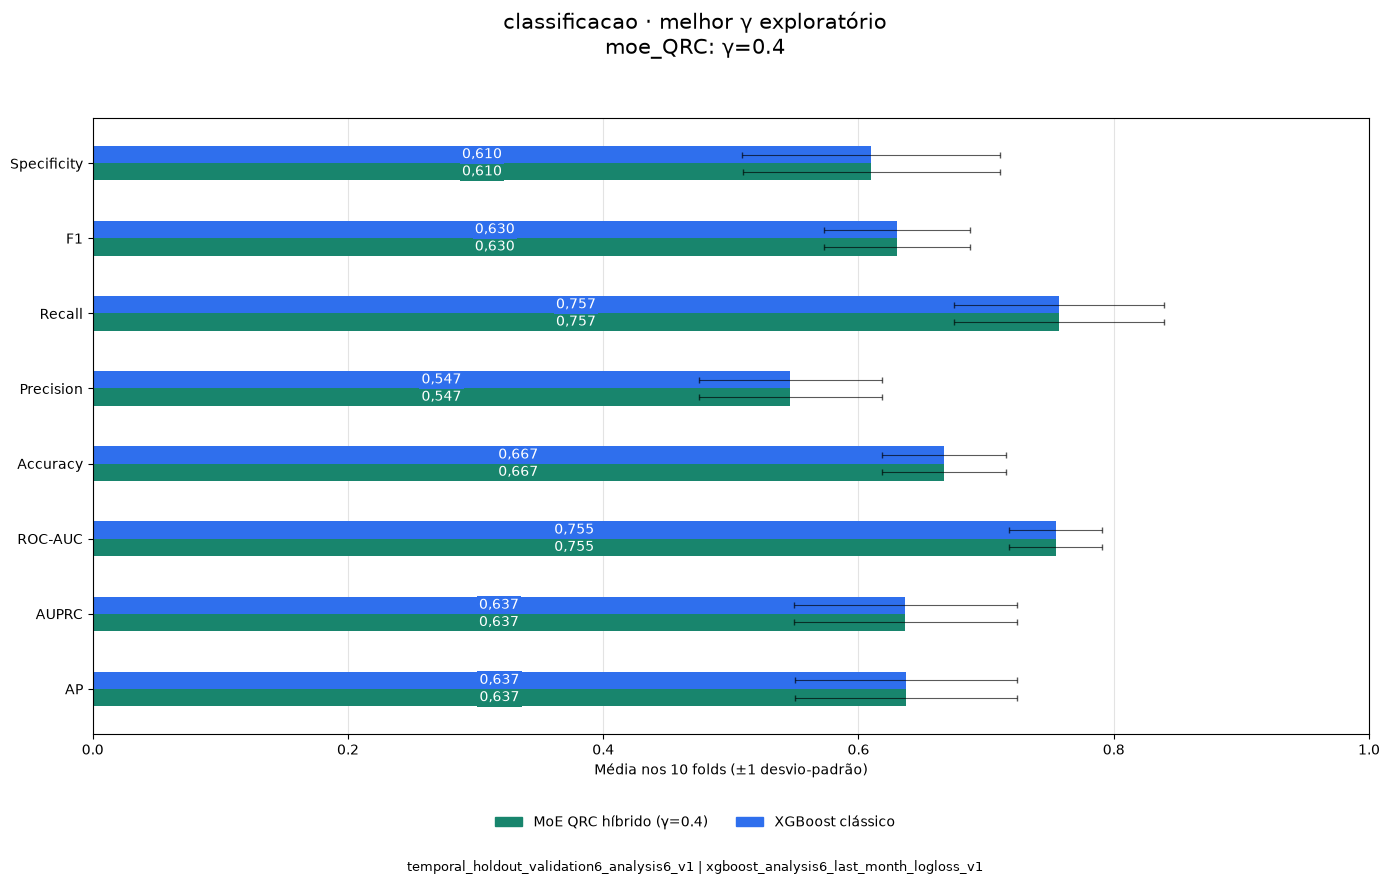

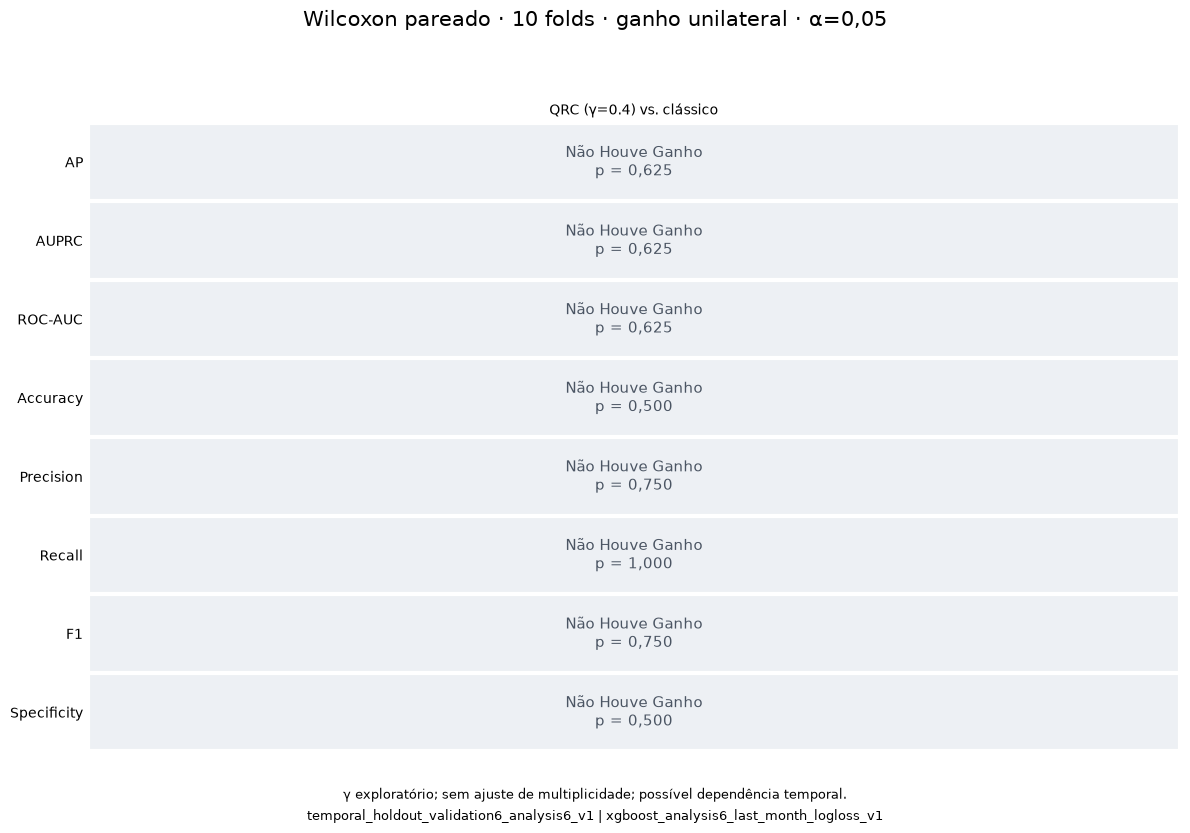

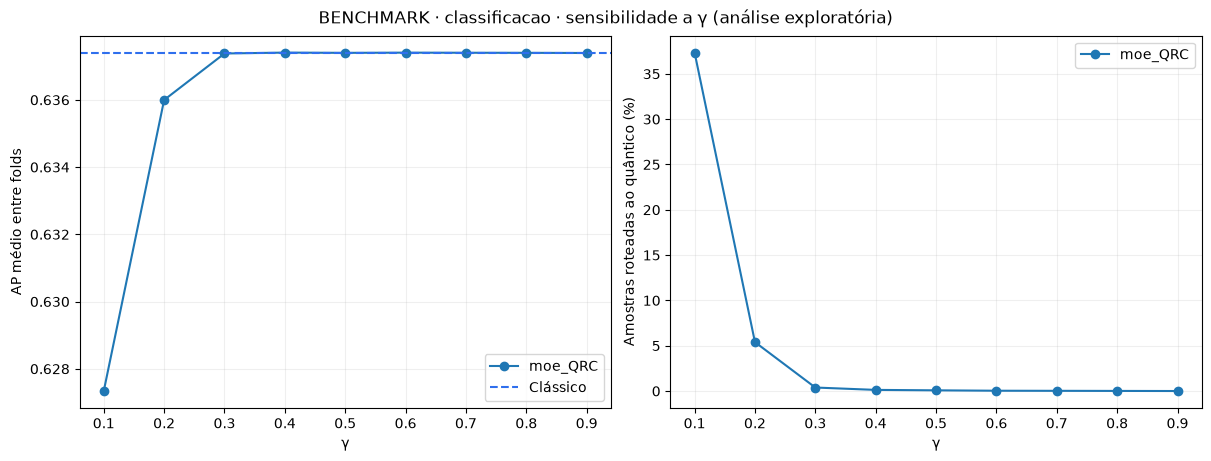

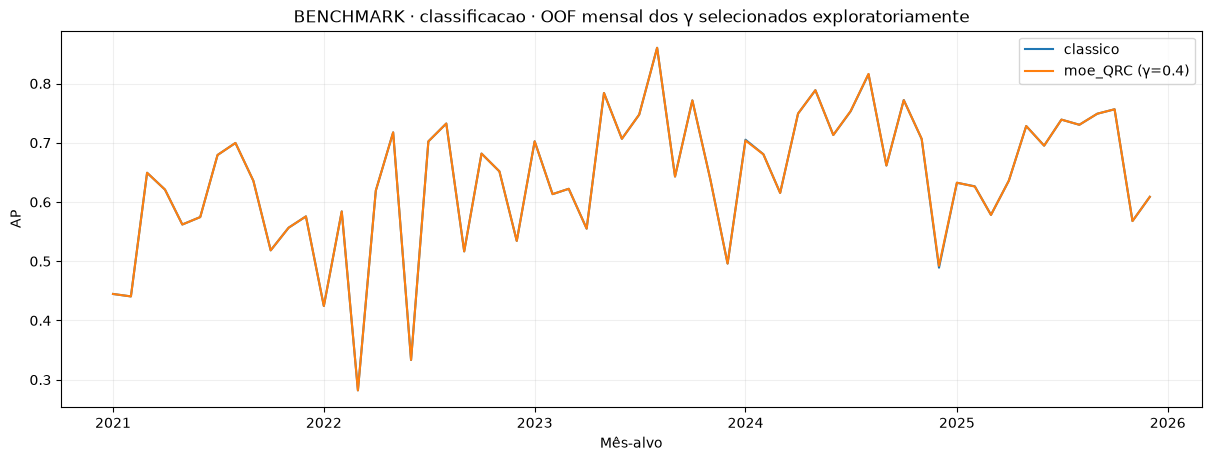

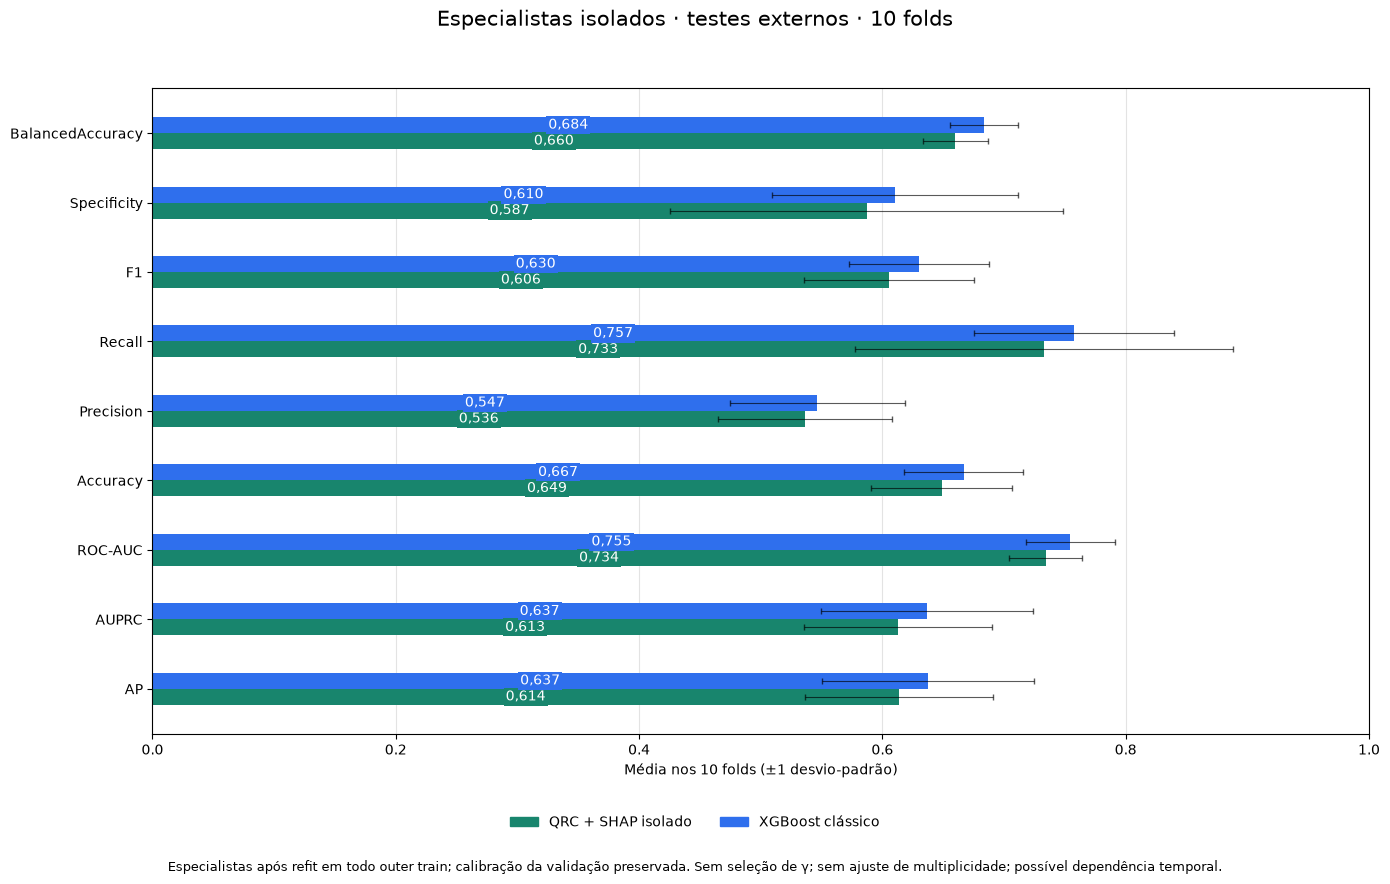

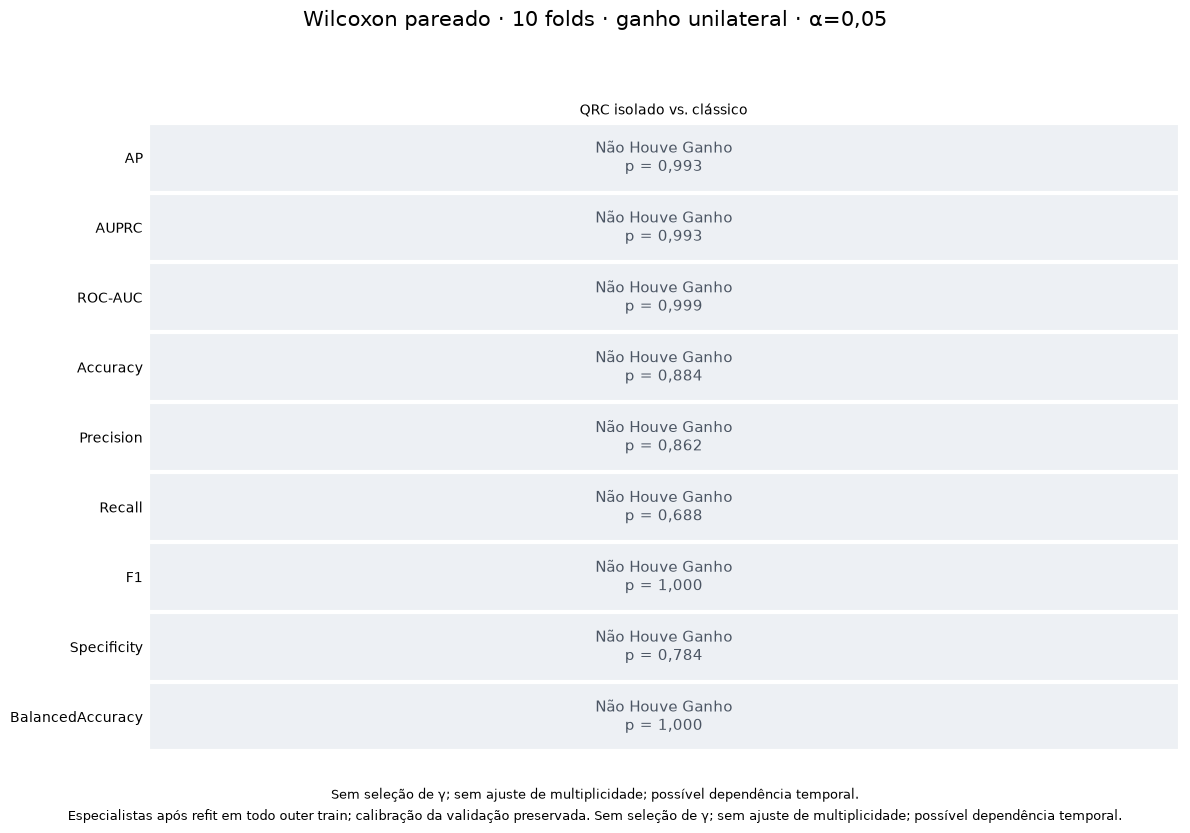

In [25]:
ANALYZE_CLASSIFICATION = True
EXPORT_CLASSIFICATION = False

if ANALYZE_CLASSIFICATION or EXPORT_CLASSIFICATION:
    if "classificacao_moe_results" not in globals():
        raise RuntimeError("Execute primeiro os cenários de classificacao.")
    classificacao_stats = moe_vs_classic_statistics(classificacao_moe_results["metrics"])
    classificacao_best = select_best_gamma_tables(classificacao_stats)
    classificacao_oof, classificacao_monthly = summarize_selected_oof(
        classificacao_moe_results, classificacao_best)
    if ANALYZE_CLASSIFICATION:
        classificacao_reference = reference_comparison_tables(classificacao_moe_results["metrics"])
        for table_name, table in classificacao_reference.items():
            print(table_name)
            display(table)
        display(classificacao_stats)
        display(classificacao_best)
        display(classificacao_oof)
        classificacao_figures = make_result_figures(
            classificacao_moe_results["metrics"], classificacao_stats, classificacao_best, classificacao_monthly, classificacao_moe_results.get("provenance"))
        if 'standalone_predictions' in classificacao_moe_results:
            classificacao_isolados_tables = standalone_comparison_tables(classificacao_moe_results)
            for name, table in classificacao_isolados_tables.items():
                print(name)
                display(table)
            classificacao_figures.update(standalone_figures(classificacao_moe_results, classificacao_isolados_tables))
        else:
            print('Resultado anterior sem especialistas isolados no teste; execute o experimento atualizado para obter essa comparação.')
        import matplotlib.pyplot as plt
        for figure in classificacao_figures.values():
            display(figure)
            plt.close(figure)
    if EXPORT_CLASSIFICATION:
        classificacao_output = export_moe_results(classificacao_moe_results, data, folds, protocol)
        print("Artefatos:", classificacao_output.resolve())


In [26]:
classificacao_output = export_moe_results(
    classificacao_moe_results, data, folds, protocol
)
print(classificacao_output.resolve())

/home/pichau/pqfmlib-api/experiments/sia/outputs/demanda_pressao_qrc_holdout/classificacao/full_20261106T000406058947Z_b2a3b857


## Limites de interpretação

Validação é reutilizada para selecionar hiperparâmetros, temperatura e threshold F1. Analysis é posterior e separado; os routers recebem alvos produzidos por especialistas que não treinaram nesse bloco. O refit final incorpora as duas reservas, mantendo calibração e routers anteriores. Essa mudança de modelos pode alterar a qualidade do roteamento.

AP, AUPRC trapezoidal, ROC-AUC, Accuracy, Precision, Recall, F1, Specificity e BalancedAccuracy são avaliadas nos testes externos. A escolha do melhor gamma é exploratória. Não confundir melhoria do MoE com avaliação do especialista secundário sozinho em todo o teste.
